# Prédire les annulations de réservations hôtelières

**Formation.** Data Analyst, Simplon Lyon

## Contexte
Un groupe hôtelier exploite deux établissements, un City Hotel et un Resort Hotel. Les annulations compliquent la prévision de l'occupation, l'organisation des équipes et le pilotage commercial. La direction veut mieux comprendre ces annulations à partir de son historique de réservations (jeu de données Hotel Booking Demand).

Ce notebook est la partie Machine Learning du projet de groupe. L'exploration et le nettoyage sont faits par Laurie et Ilyes dans le notebook `Hotel_bookings`. On part du fichier nettoyé `reservations_nettoyees.csv` qui en est issu. Nos analyses et nos choix de colonnes s'appuient sur ces deux fichiers.

## Objectifs
- Préparer les données pour la modélisation (colonnes retenues, split, encodage, standardisation)
- Entraîner et comparer des modèles de classification dont une régression logistique
-Tester les paramètres de chaque modèle et comparer leurs effets
- Évaluer les modèles et choisir le meilleur
- Analyser les erreurs et les limites du modèle
- Identifier les variables qui pèsent le plus dans les annulations

## Plan

1. Cadrage et chargement des données
2. Pré-nettoyage
3. Split
4. Nettoyage après le split
5. Modèles
6. Premiers résultats
7. Ajustement des paramètres
8. Importance des variables
9. Choix du modèle
10. Analyse des erreurs
11. Conclusion

## 1. Cadrage et chargement des données

### 1.1 Cadrage

**Question du client**
Dans quelle mesure les informations connues au moment d'une réservation permettent-elles d'anticiper son annulation ? Et quelles variables pèsent le plus ?

**Cible et type de problème**
La cible est `est_annule`. 1 veut dire annulée ou no-show. 0 veut dire que le séjour a eu lieu.

**Moment de la prédiction**
La prédiction se fait au jour de la réservation.

### 1.2 Import des librairies

In [52]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

### 1.3 Chargement et contrôle du CSV

In [2]:
# Charge le CSV nettoyé de Laurie et contrôle sa taille, ses colonnes et la part d'annulations
df = pd.read_csv('../data/reservations_nettoyees.csv')
print(df.shape)
print(df.columns.tolist())
print(df['est_annule'].value_counts())
print(df['est_annule'].value_counts(normalize=True))

(86637, 40)
['hotel', 'est_annule', 'delai_reservation_jours', 'annee_arrivee', 'mois_arrivee', 'semaine_arrivee', 'jour_arrivee', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'formule_repas', 'pays', 'segment_marche', 'canal_distribution', 'client_fidele', 'annulations_precedentes', 'reservations_precedentes_non_annulees', 'type_chambre_reservee', 'type_chambre_attribuee', 'nb_modifications', 'type_acompte', 'id_agent', 'id_entreprise', 'jours_liste_attente', 'type_client', 'prix_moyen_nuit', 'places_parking', 'nb_demandes_speciales', 'statut_reservation', 'date_statut_reservation', 'duree_sejour', 'total_revenue', 'date_arrivee', 'lead_time_bins', 'tranche_delai', 'num_mois', 'periode', 'type_sejour']
est_annule
0    62652
1    23985
Name: count, dtype: int64
est_annule
0    0.723155
1    0.276845
Name: proportion, dtype: float64


Le fichier contient 86 637 réservations et 40 colonnes. Les 8 dernières de la liste (de `duree_sejour` à `type_sejour`) ont été créées par Laurie pour ses analyses. Elles ne font pas partie des données d'origine. On les retire en 2.1.

La cible `est_annule` vaut 0 pour 62 652 réservations (72,3 %) et 1 pour 23 985 réservations (27,7 %). La classe annulée est la moins fréquente.

<a id="prenettoyage"></a>
## 2. Pré-nettoyage

Dans cette partie on applique seulement des règles fixes. Rien n'est calculé à partir des données (pas de moyenne ni d'écart type). Tout ce qui apprend quelque chose des données est fait après le split sur le train uniquement. Comme ça le jeu de test n'influence pas la préparation.

### 2.1 Retrait des colonnes

On garde les variables retenues et la cible. Toutes les autres colonnes sont retirées. Ce premier tri s'appuie sur le notebook de Laurie et sur la description Kaggle des colonnes. Quand une affirmation vient d'un test sur les données, le test est juste en dessous.

**Les colonnes de Laurie.** Elles ont été créées pour ses analyses et ne font pas partie des données d'origine. On les voit à la fin de la liste des colonnes en 1.3. Ce sont `duree_sejour`, `total_revenue`, `date_arrivee`, `lead_time_bins`, `tranche_delai`, `num_mois`, `periode` et `type_sejour`. Elles sont calculées à partir d'autres colonnes et `total_revenue` utilise le prix.

**Les colonnes qui donnent la réponse.** `statut_reservation` donne la cible. `date_statut_reservation` est, d'après la description Kaggle, la date du dernier statut de la réservation. Elle sert à savoir quand la réservation a été annulée ou quand le client est parti. On ne la connaît donc qu'à la fin.

**Les colonnes qui ne sont pas connues avec certitude à la réservation.** D'après la description Kaggle, `nb_modifications` compte les changements faits entre la saisie de la réservation et l'arrivée ou l'annulation. `jours_liste_attente` est le nombre de jours passés en liste d'attente avant la confirmation au client. `type_chambre_attribuee` peut différer de la chambre réservée à cause de l'hôtel ou d'une demande du client. `places_parking` est une demande du client dont la description ne donne pas le moment. Le test montre qu'aucune réservation avec une place demandée n'est annulée.

**Les colonnes sans intérêt ou en doublon.** `nb_demandes_speciales` est, d'après la description Kaggle, le nombre de demandes spéciales faites par le client. Un nombre seul ne dit pas quelles demandes ont été faites ni si l'hôtel a pu les satisfaire. `canal_distribution` et `segment_marche` décrivent tous les deux la façon dont la réservation est arrivée. Le tableau croisé plus bas montre que presque chaque segment tombe dans un seul canal. On garde le segment car il est plus détaillé. `id_entreprise` est un numéro anonymisé et elle est vide pour la grande majorité des réservations.

**Les dates d'arrivée.** On garde le mois pour la saisonnalité. `annee_arrivee` est retirée car une future réservation aura une année que le modèle n'a jamais vue. Les données vont de juillet 2015 à août 2017. `semaine_arrivee` coupe le mois et le jour du mois n'a pas de sens pour l'hôtel.

**Le prix.** `prix_moyen_nuit` est calculée à partir de toutes les transactions d'hébergement divisées par le nombre de nuits (description Kaggle). On ne peut pas dire que ce prix est fixé au moment de la réservation. On la retire.

In [3]:
# Regarde le taux d'annulation selon le nombre de places de parking demandées
df.groupby('places_parking')['est_annule'].agg(taux='mean', nb='count')

,taux,nb
places_parking,,
0,0.30228,79347
1,0.00000,7257
2,0.00000,28
3,0.00000,3
8,0.00000,2


In [4]:
# Croise le segment de marché avec le canal de distribution
pd.crosstab(df['segment_marche'], df['canal_distribution'])

canal_distribution,Corporate,Direct,GDS,TA/TO,Undefined
segment_marche,,,,,
Aviation,212,0,0,10,0
Complementary,77,530,0,75,0
Corporate,3850,152,0,153,0
Direct,80,11341,1,228,2
Groups,654,638,0,3599,0
Offline TA/TO,94,16,44,13594,0
Online TA,34,126,133,50991,1
Undefined,0,0,0,0,2


In [5]:
# Garde les variables retenues et la cible, retire toutes les autres colonnes
colonnes_gardees = ['hotel', 'mois_arrivee', 'formule_repas', 'pays', 'segment_marche',
                    'type_chambre_reservee', 'type_acompte', 'id_agent', 'type_client',
                    'delai_reservation_jours', 'nuits_weekend', 'nuits_semaine',
                    'adultes', 'enfants', 'bebes', 'client_fidele',
                    'annulations_precedentes', 'reservations_precedentes_non_annulees']

df_ml = df[colonnes_gardees + ['est_annule']].copy()
print(df_ml.shape)
print(df.columns.difference(df_ml.columns).tolist())

(86637, 19)
['annee_arrivee', 'canal_distribution', 'date_arrivee', 'date_statut_reservation', 'duree_sejour', 'id_entreprise', 'jour_arrivee', 'jours_liste_attente', 'lead_time_bins', 'nb_demandes_speciales', 'nb_modifications', 'num_mois', 'periode', 'places_parking', 'prix_moyen_nuit', 'semaine_arrivee', 'statut_reservation', 'total_revenue', 'tranche_delai', 'type_chambre_attribuee', 'type_sejour']


### 2.2 Valeurs manquantes

Ici on regarde les valeurs manquantes des colonnes gardées. Avant le split on traite seulement ce qui se règle avec une règle fixe. Tout ce qui demande de calculer une valeur à partir des données est fait en 4.1, après le split.

In [6]:
# Compte les valeurs manquantes des colonnes gardées
manquants = df_ml.isna().sum()
manquants[manquants > 0]

pays          442
id_agent    11958
enfants         4
dtype: int64

In [7]:
# Compte la valeur "Undefined" dans chaque colonne texte gardée
for col in df_ml.select_dtypes(exclude='number').columns:
    print(col, (df_ml[col] == 'Undefined').sum())

hotel 0
mois_arrivee 0
formule_repas 485
pays 0
segment_marche 2
type_chambre_reservee 0
type_acompte 0
type_client 0


In [8]:
# Regroupe Undefined avec SC dans formule_repas (même catégorie d'après la description Kaggle)
df_ml['formule_repas'] = df_ml['formule_repas'].replace('Undefined', 'SC')
df_ml['formule_repas'].value_counts()

formule_repas
BB    67417
SC     9831
HB     9030
FB      359
Name: count, dtype: int64

In [9]:
# Remplace les pays manquants par la catégorie "Inconnu"
df_ml['pays'] = df_ml['pays'].fillna('Inconnu')

In [10]:
# Transforme id_agent en catégorie (texte) et met "Non renseigné" pour les manquants
df_ml['id_agent'] = df_ml['id_agent'].apply(lambda x: 'Non renseigné' if pd.isna(x) else str(int(x)))

In [11]:
# Vérifie ce qui reste comme valeurs manquantes
manquants = df_ml.isna().sum()
manquants[manquants > 0]

enfants    4
dtype: int64

**Pays.** 442 réservations n'ont pas de pays. On les met dans une catégorie "Inconnu". C'est une règle fixe et on garde les lignes.

**Agent.** D'après la description Kaggle, `id_agent` est l'identifiant de l'agence qui a fait la réservation. C'est un numéro et pas une quantité. On le transforme donc en catégorie. 11 958 réservations n'ont pas d'agent renseigné. On les met dans une catégorie "Non renseigné". On ne parle pas de "sans agent" car un manquant ne veut pas forcément dire absence d'agent.

**Enfants.** 4 valeurs manquantes. Les remplacer par une médiane demande de la calculer sur les données. On le fait en 4.1, après le split.

**Segment de marché.** 2 réservations ont le segment `Undefined`. C'est très peu. On les garde telles quelles.

### 2.3 Variable pays

La colonne `pays` a beaucoup de valeurs différentes. On regarde combien il y en a et comment les réservations se répartissent. On pourra ensuite choisir comment les regrouper.

In [12]:
# Compte les pays différents et regarde les 15 plus fréquents
print(df_ml['pays'].nunique())
vc = df_ml['pays'].value_counts()
pd.DataFrame({'nb': vc, 'part': (vc / len(df_ml)).round(3)}).head(15)

178


,nb,part
pays,,
PRT,26863,0.310
GBR,10400,0.120
FRA,8813,0.102
ESP,7228,0.083
DEU,5385,0.062
ITA,3056,0.035
IRL,3014,0.035
BEL,2078,0.024
BRA,1988,0.023


In [13]:
# Taux d'annulation et nombre de réservations des 10 pays les plus fréquents
top = df_ml['pays'].value_counts().head(10).index
df_ml[df_ml['pays'].isin(top)].groupby('pays')['est_annule'].agg(taux='mean', nb='count').sort_values('nb', ascending=False)

,taux,nb
pays,,
PRT,0.363660,26863
GBR,0.190673,10400
FRA,0.196414,8813
ESP,0.257471,7228
DEU,0.195543,5385
ITA,0.351440,3056
IRL,0.221632,3014
BEL,0.197305,2078
BRA,0.365191,1988


La colonne `pays` a 178 valeurs différentes (la catégorie "Inconnu" comprise). Le Portugal domine avec 26 863 réservations, soit 31,0 % du total. Viennent ensuite le Royaume-Uni (12,0 %), la France (10,2 %) et l'Espagne (8,3 %). Dès le 14e pays, la part est d'environ 1 %.

Le taux d'annulation change d'un pays à l'autre. Il est de 36,4 % pour le Portugal, 36,5 % pour le Brésil et 35,1 % pour l'Italie. Il tombe à 18,3 % pour les Pays-Bas et 19,1 % pour le Royaume-Uni. Le taux global est de 27,7 % (voir 1.3).

Un one-hot complet ferait 178 colonnes. On garde donc les pays les plus fréquents et on regroupe tous les autres dans "Autres". Les pays très présents comme le Portugal restent visibles. Le regroupement se fait en 4.2. La liste des pays rares se calcule sur le train, donc le seuil sera fixé à ce moment-là.

### 2.4 encodage binaire

Une colonne qui n'a que deux valeurs se transforme en 0 et 1 avec une règle fixe. Rien n'est calculé à partir des données, donc on peut le faire avant le split. C'est le cas de `hotel`. Les autres colonnes texte ont plus de deux valeurs et sont encodées en 4.2.

In [14]:
# Transforme hotel en 0/1 avec une règle fixe (Resort Hotel = 0 et City Hotel = 1)
df_ml['hotel'] = df_ml['hotel'].map({'Resort Hotel': 0, 'City Hotel': 1})
df_ml['hotel'].value_counts()

hotel
1    53042
0    33595
Name: count, dtype: int64

`hotel` est maintenant en 0 et 1. Le City Hotel vaut 1 (53 042 réservations) et le Resort Hotel vaut 0 (33 595 réservations). Ça fait bien les 86 637 réservations de 1.3, donc aucune valeur n'a été perdue.

### 2.5 Bilan avant le split

On vérifie l'état de `df_ml` avant de le couper en train et test. On regarde sa taille, le type des colonnes et ce qui reste de valeurs manquantes.

In [15]:
# Résume df_ml : taille, types des colonnes et valeurs non manquantes
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86637 entries, 0 to 86636
Data columns (total 19 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   hotel                                  86637 non-null  int64  
 1   mois_arrivee                           86637 non-null  object 
 2   formule_repas                          86637 non-null  object 
 3   pays                                   86637 non-null  object 
 4   segment_marche                         86637 non-null  object 
 5   type_chambre_reservee                  86637 non-null  object 
 6   type_acompte                           86637 non-null  object 
 7   id_agent                               86637 non-null  object 
 8   type_client                            86637 non-null  object 
 9   delai_reservation_jours                86637 non-null  int64  
 10  nuits_weekend                          86637 non-null  int64  
 11  nu

In [16]:
# Liste les colonnes texte qui restent à encoder en 4.2
df_ml.select_dtypes(exclude='number').columns.tolist()

['mois_arrivee',
 'formule_repas',
 'pays',
 'segment_marche',
 'type_chambre_reservee',
 'type_acompte',
 'id_agent',
 'type_client']

**Bilan**

`df_ml` a 86 637 lignes et 19 colonnes, la cible `est_annule` comprise. Il ne manque plus aucune valeur sauf pour `enfants` qui en a 4. Elles sont remplacées en 4.1, après le split.

Les colonnes texte qui restent sont `mois_arrivee`, `formule_repas`, `pays`, `segment_marche`, `type_chambre_reservee`, `type_acompte`, `id_agent` et `type_client`. Elles sont encodées en 4.2. Toutes les autres colonnes sont numériques.

Le prétraitement avant le split est terminé.

## 3.Split

On sépare les données en deux parties. Le train sert à apprendre et le test sert à évaluer à la fin. Le test n'est utilisé qu'une seule fois, pour juger le modèle final.

### 3.1 Variables explicatives et cible

In [17]:
# Sépare les variables explicatives (X) de la cible (y)
X = df_ml.drop(columns='est_annule')
y = df_ml['est_annule']
print(X.shape, y.shape)

(86637, 18) (86637,)


### 3.2 Split 80/20

On garde 80 % des réservations pour le train et 20 % pour le test. Le split est stratifié sur `est_annule` donc le train et le test gardent ainsi la même part d'annulations que l'ensemble des données. On fixe `random_state` pour retrouver le même découpage à chaque lancement.

In [18]:
# Sépare les données en train (80 %) et test (20 %) en gardant la même part d'annulations
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(69309, 18) (17328, 18)


### 3.3 Vérification

On vérifie les tailles du train et du test et la part d'annulations dans chacun.

In [19]:
# Compare la part d'annulations dans l'ensemble, le train et le test
print(y.value_counts(normalize=True))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

est_annule
0    0.723155
1    0.276845
Name: proportion, dtype: float64
est_annule
0    0.723153
1    0.276847
Name: proportion, dtype: float64
est_annule
0    0.723165
1    0.276835
Name: proportion, dtype: float64


Le train compte 69 309 réservations et le test 17 328, avec 18 variables chacun. La part d'annulations est de 27,7 % dans l'ensemble des données, dans le train et dans le test. Les trois proportions sont identiques jusqu'à la quatrième décimale. Le split stratifié a bien gardé la même part d'annulations des deux côtés.

<a id="postsplit"></a>
## 4. Nettoyage après le split

Ici on applique ce qui apprend quelque chose des données (une médiane, la liste des catégories, une moyenne). Chaque outil apprend sur le train uniquement, puis on l'applique au train et au test. Le test ne joue donc aucun rôle dans la préparation.

### 4.1 Imputation

Seule la colonne `enfants` a encore des valeurs manquantes. On les remplace par la médiane calculée sur le train.

In [20]:
# Remplace les enfants manquants par la médiane du train, apprise sur le train puis appliquée au test
imputeur = SimpleImputer(strategy='median')
X_train['enfants'] = imputeur.fit_transform(X_train[['enfants']])
X_test['enfants'] = imputeur.transform(X_test[['enfants']])
print(imputeur.statistics_)
print(X_train['enfants'].isna().sum(), X_test['enfants'].isna().sum())

[0.]
0 0


La médiane des enfants apprise sur le train est 0. Les valeurs manquantes de `enfants` sont donc remplacées par 0. Ça veut dire qu'au moins la moitié des réservations du train n'ont pas d'enfant. Il ne reste plus aucune valeur manquante dans le train ni dans le test.

### 4.2 Encodage des variables catégorielles

Les colonnes texte qui restent sont `mois_arrivee`, `formule_repas`, `pays`, `segment_marche`, `type_chambre_reservee`, `type_acompte`, `id_agent` et `type_client`. On les encode en one-hot, avec une colonne 0/1 par catégorie. L'encodeur apprend la liste des catégories sur le train, puis on l'applique au train et au test. Pour `pays` et `id_agent`, qui ont beaucoup de catégories, les plus rares sont regroupées dans "Autres".

**Colonnes sans regroupement.** On encode d'abord `mois_arrivee`, `formule_repas`, `segment_marche`, `type_chambre_reservee`, `type_acompte` et `type_client`. L'encodeur apprend la liste des catégories sur le train (`fit_transform`) puis on l'applique au test (`transform`).

In [21]:
# Encode en one-hot les 6 colonnes sans regroupement : la grille est apprise sur le train puis appliquée au test
colonnes_simples = ['mois_arrivee', 'formule_repas', 'segment_marche', 'type_chambre_reservee', 'type_acompte', 'type_client']

encodeur_simple = OneHotEncoder(handle_unknown='ignore', sparse_output=False)   # l'outil one-hot (ignore = Si test connait pas une colonne, sparse= tab)
noms = encodeur_simple.fit(X_train[colonnes_simples]).get_feature_names_out(colonnes_simples)   # apprend la grille sur le train et note les noms de colonnes

train_simple = pd.DataFrame(encodeur_simple.transform(X_train[colonnes_simples]), columns=noms, index=X_train.index)   # remplit la grille pour le train
test_simple = pd.DataFrame(encodeur_simple.transform(X_test[colonnes_simples]), columns=noms, index=X_test.index)      # remplit la même grille pour le test
print(train_simple.shape, test_simple.shape)

(69309, 40) (17328, 40)


In [22]:
# Affiche le nombre de catégories apprises pour chaque colonne
for nom, cat in zip(colonnes_simples, encodeur_simple.categories_):
    print(nom, len(cat))

mois_arrivee 12
formule_repas 4
segment_marche 8
type_chambre_reservee 9
type_acompte 3
type_client 4


Les 6 colonnes ont respectivement 12, 4, 8, 9, 3 et 4 catégories. Chaque catégorie devient une colonne 0/1, ce qui fait 40 colonnes. Le train et le test ont le même nombre de colonnes et gardent leur nombre de lignes (69 309 et 17 328).

Ces colonnes sont dans des tables provisoires : `train_simple` et `test_simple`. Les colonnes texte d'origine restent dans `X_train` et `X_test`. On les retire à l'assemblage, à la fin de 4.2.

**Pays.** 

`pays` a beaucoup de catégories. On garde chaque pays assez fréquent dans sa propre colonne et on regroupe les pays rares dans "Autres". La fréquence se mesure sur le train.

In [23]:
# Compte les pays gardés et la part des réservations qu'ils couvrent, selon le seuil choisi
vc = X_train['pays'].value_counts()                  # nombre de réservations de chaque pays dans le train
for seuil in [50, 100, 200, 500]:                    # essaie quatre seuils, un après l'autre
    gardes = vc[vc >= seuil]                         # pays qui ont au moins "seuil" réservations
    print(seuil, len(gardes), round(gardes.sum() / len(X_train), 3))

50 44 0.98
100 34 0.97
200 27 0.955
500 17 0.907


In [24]:
seuil_pays = 200

In [25]:
# One-hot de pays : les pays qui ont moins de seuil_pays réservations dans le train vont dans "Autres"
encodeur_pays = OneHotEncoder(min_frequency=seuil_pays, handle_unknown='infrequent_if_exist', sparse_output=False)
encodeur_pays.fit(X_train[['pays']])

# Récupère les noms des nouvelles colonnes
noms_pays = encodeur_pays.get_feature_names_out(['pays'])

train_pays = pd.DataFrame(encodeur_pays.transform(X_train[['pays']]), columns=noms_pays, index=X_train.index)
test_pays = pd.DataFrame(encodeur_pays.transform(X_test[['pays']]), columns=noms_pays, index=X_test.index)

print(train_pays.shape, test_pays.shape)
print(noms_pays[-3:])

(69309, 28) (17328, 28)
['pays_SWE' 'pays_USA' 'pays_infrequent_sklearn']


Avec un seuil de 200 réservations, `pays` donne 28 colonnes. Ce sont 27 pays gardés chacun dans leur colonne et une colonne `pays_infrequent_sklearn` qui regroupe tous les pays rares sous le nom "Autres". Le train et le test ont le même nombre de colonnes (28). Les nombres de lignes restent 69 309 et 17 328.

**Agent.** `id_agent` est un numéro d'agence. On le traite comme une catégorie. Comme pour `pays`, un agent qui a moins de réservations que le seuil dans le train est regroupé dans "Autres". La catégorie "Non renseigné" suit la même règle que les autres.

In [26]:
# Compte les agents gardés et la part des réservations qu'ils couvrent, selon le seuil choisi
vc = X_train['id_agent'].value_counts()              # nombre de réservations de chaque agent dans le train
print('agents au total :', len(vc))
for seuil in [50, 100, 150, 200, 500]:                    # essaie quatre seuils, un après l'autre
    gardes = vc[vc >= seuil]                         # agents qui ont au moins "seuil" réservations
    print(seuil, len(gardes), round(gardes.sum() / len(X_train), 3))

agents au total : 319
50 77 0.964
100 52 0.94
150 35 0.908
200 27 0.889
500 14 0.834


In [27]:
seuil_agent = 150

In [28]:
# One-hot de id_agent : les agents qui ont moins de seuil_agent réservations dans le train vont dans "Autres"
encodeur_agent = OneHotEncoder(min_frequency=seuil_agent, handle_unknown='infrequent_if_exist', sparse_output=False)

encodeur_agent.fit(X_train[['id_agent']])

# Récupère les noms des nouvelles colonnes
noms_agent = encodeur_agent.get_feature_names_out(['id_agent'])

train_agent = pd.DataFrame(encodeur_agent.transform(X_train[['id_agent']]), columns=noms_agent, index=X_train.index)
test_agent = pd.DataFrame(encodeur_agent.transform(X_test[['id_agent']]), columns=noms_agent, index=X_test.index)

print(train_agent.shape, test_agent.shape)
print(noms_agent[-3:])

(69309, 36) (17328, 36)
['id_agent_96' 'id_agent_Non renseigné' 'id_agent_infrequent_sklearn']


Pour `id_agent`, un agent qui a moins de 150 réservations dans le train est regroupé dans "Autres". Le seuil est la variable `seuil_agent`. Avec 150, 35 agents gardent leur propre colonne et couvrent 90,8 % des réservations du train. Avec la colonne "Autres" (`id_agent_infrequent_sklearn`), ça fait 36 colonnes. La catégorie "Non renseigné" garde sa propre colonne. Le train et le test ont le même nombre de colonnes (36).

**Assemblage.** On crée deux nouvelles tables, `X_train_final` et `X_test_final`. Chacun regroupe les colonnes 0/1 des trois encodages (colonnes simples, `pays` et `id_agent`) et les 10 colonnes de `X_train` et `X_test` qui n'avaient pas besoin d'être encodées. Les 8 colonnes texte ne sont pas reprises. `X_train` et `X_test` ne changent pas. Les colonnes sont recollées ligne par ligne grâce au numéro de ligne d'origine, conservé dans chaque table.

In [29]:
# Liste les 8 colonnes texte qui viennent d'être encodées
colonnes_texte = ['mois_arrivee', 'formule_repas', 'pays', 'segment_marche', 'type_chambre_reservee', 'type_acompte', 'id_agent', 'type_client']

# Retire ces colonnes texte et recolle côte à côte les trois tableaux de colonnes 0/1 (axis=1 = en largeur)
X_train_enco = pd.concat([X_train.drop(columns=colonnes_texte), train_simple, train_pays, train_agent], axis=1)
X_test_enco = pd.concat([X_test.drop(columns=colonnes_texte), test_simple, test_pays, test_agent], axis=1)

print(X_train_enco.shape, X_test_enco.shape)

(69309, 114) (17328, 114)


In [30]:
# Vérifie que le train et le test ont les mêmes colonnes, qu'il n'y a plus de texte ni de valeur manquante
print(list(X_train_enco.columns) == list(X_test_enco.columns))
print(X_train_enco.select_dtypes(exclude='number').columns.tolist())
print(X_train_enco.isna().sum().sum(), X_test_enco.isna().sum().sum())

True
[]
0 0


`X_train_enco` a 69 309 lignes et 114 colonnes. `X_test_enco` a 17 328 lignes et 114 colonnes. Ces 114 colonnes sont les 10 colonnes qui n'avaient pas besoin d'être encodées plus les 40, 28 et 36 colonnes des trois encodages. Le train et le test ont exactement les mêmes colonnes, dans le même ordre. Il ne reste aucune colonne texte et aucune valeur manquante.

### 4.3 Log & Standardisation

Seules les 8 colonnes numériques d'origine sont concernées. Les colonnes 0/1 (`hotel`, `client_fidele` et toutes celles issues du one-hot) sont déjà entre 0 et 1. On regarde d'abord la forme de ces 8 colonnes sur le train pour voir si une mise à l'échelle est nécessaire.

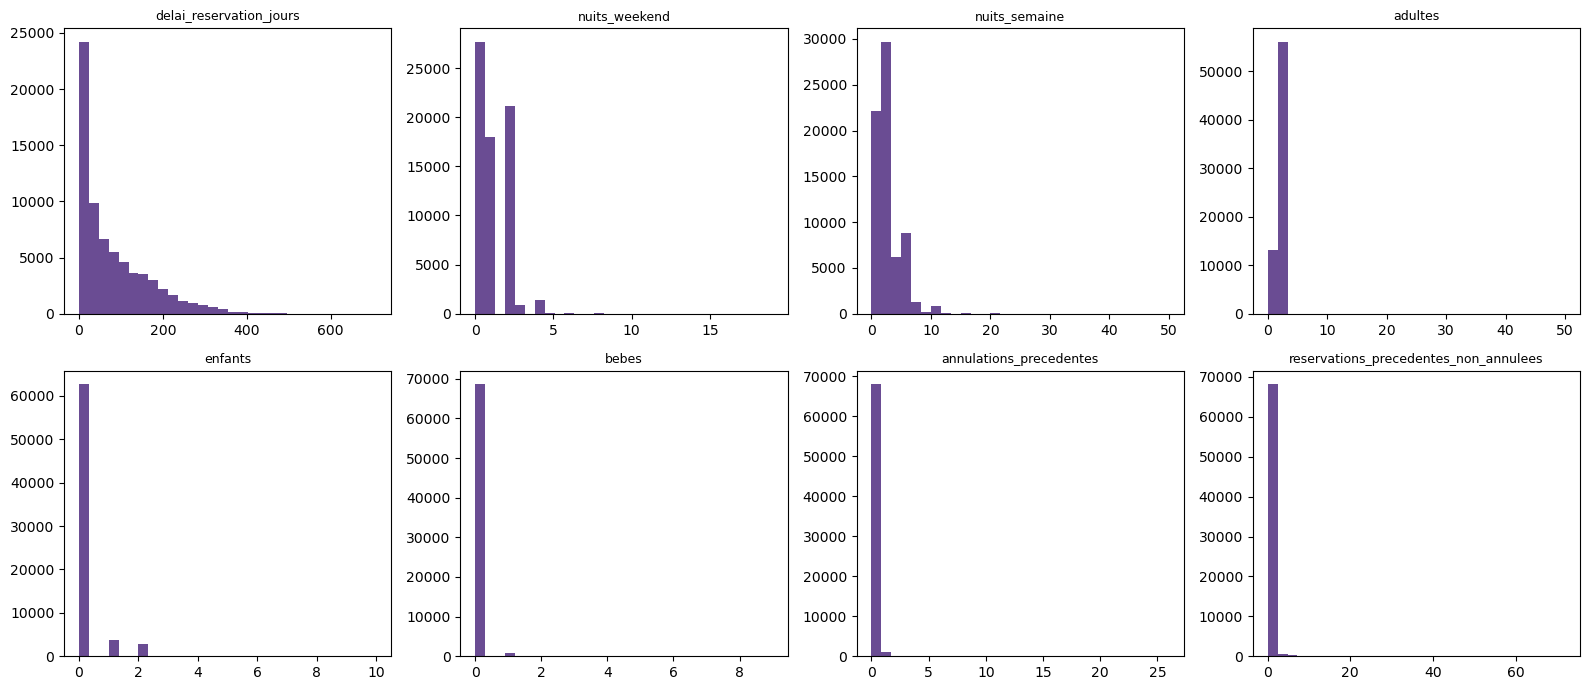

C:\Users\ludiv\Documents\Simplon\Brief groupe\Hotel_Booking Ilyes Laurie\projet_hotel_booking\assets\graphiques\histogrammes_numeriques.png


In [31]:
# Trace un histogramme pour chacune des 8 colonnes numériques du train et l'enregistre sur le PC
colonnes_numeriques = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']

os.makedirs('../assets/graphiques', exist_ok=True)                 

fig, axes = plt.subplots(2, 4, figsize=(16, 7))              # une grille de 2 lignes et 4 colonnes de graphiques
for ax, col in zip(axes.ravel(), colonnes_numeriques):       
    ax.hist(X_train_enco[col], bins=30, color='#6A4C93')    # histogramme : combien de réservations par valeur
    ax.set_title(col, fontsize=9)                            
plt.tight_layout()                                           # évite que les titres se chevauchent
plt.savefig('../assets/graphiques/histogrammes_numeriques.png', dpi=150, bbox_inches='tight')   # enregistre l'image
plt.show()                                                   
print(os.path.abspath('../assets/graphiques/histogrammes_numeriques.png')) 

In [32]:
X_train_enco[colonnes_numeriques].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
delai_reservation_jours,69309.0,80.03,85.91,0.0,12.0,49.0,125.0,709.0
nuits_weekend,69309.0,1.01,1.03,0.0,0.0,1.0,2.0,19.0
nuits_semaine,69309.0,2.64,2.03,0.0,1.0,2.0,4.0,50.0
adultes,69309.0,1.88,0.59,0.0,2.0,2.0,2.0,50.0
enfants,69309.0,0.14,0.46,0.0,0.0,0.0,0.0,10.0
bebes,69309.0,0.01,0.11,0.0,0.0,0.0,0.0,9.0
annulations_precedentes,69309.0,0.03,0.38,0.0,0.0,0.0,0.0,26.0
reservations_precedentes_non_annulees,69309.0,0.19,1.76,0.0,0.0,0.0,0.0,72.0


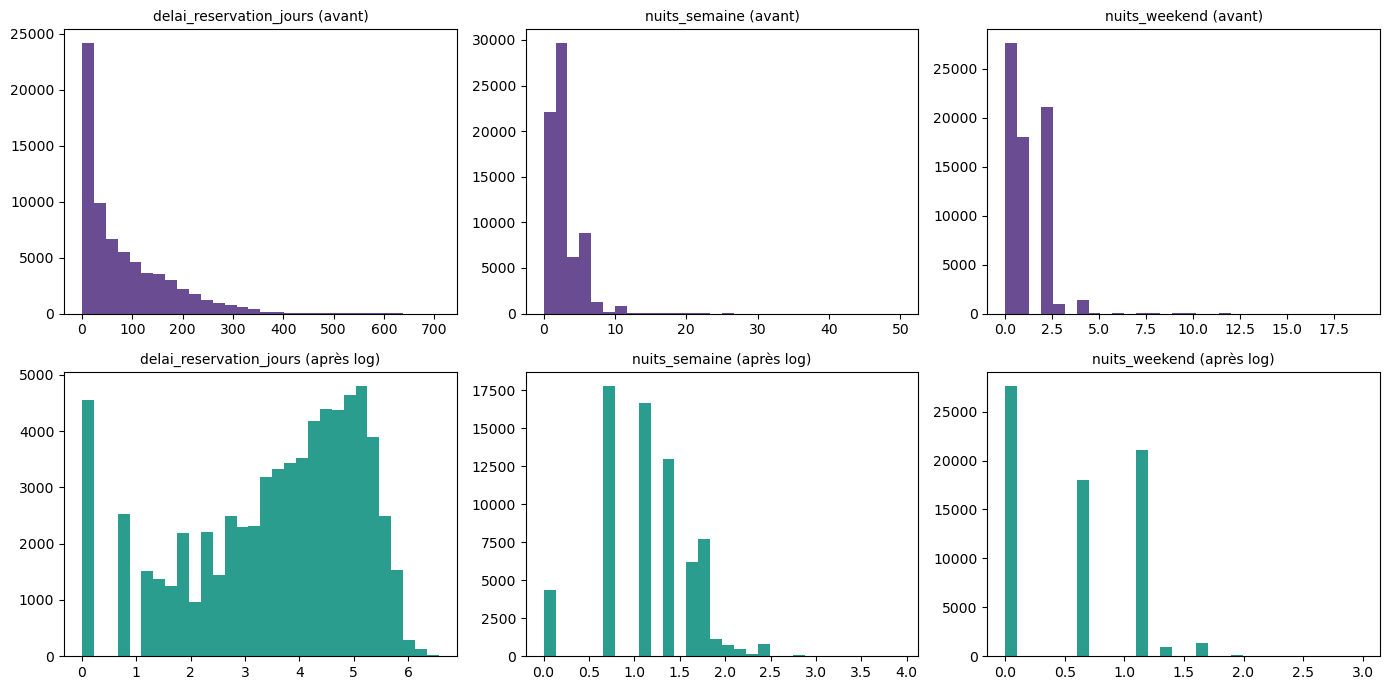

In [33]:
# Compare la forme de 3 colonnes avant et après log (log1p) et enregistre l'image
cols_log = ['delai_reservation_jours', 'nuits_semaine', 'nuits_weekend']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))                              # 2 lignes (avant, après) et 3 colonnes
for i, col in enumerate(cols_log):
    axes[0, i].hist(X_train_enco[col], bins=30, color='#6A4C93')            # ligne du haut : valeurs d'origine
    axes[0, i].set_title(col + ' (avant)', fontsize=10)
    axes[1, i].hist(np.log1p(X_train_enco[col]), bins=30, color='#2A9D8F')  # ligne du bas : après log1p
    axes[1, i].set_title(col + ' (après log)', fontsize=10)
plt.tight_layout()
plt.savefig('../assets/graphiques/avant_apres_log.png', dpi=150, bbox_inches='tight')
plt.show()

**Choix de la mise à l'échelle**

Les 8 colonnes numériques n'ont ni la même forme ni la même échelle.

Pour la forme, `delai_reservation_jours` est très étalé vers les grandes valeurs. Beaucoup de réservations sont faites peu de temps avant l'arrivée et quelques-unes très longtemps avant. `nuits_semaine` est étalée de la même façon. `adultes` est concentrée sur 1 et 2. `enfants`, `bebes`, `annulations_precedentes` et `reservations_precedentes_non_annulees` sont presque toujours à 0.

Pour l'échelle, le délai va de 0 à 709 avec un écart type de 85,9. `bebes` va de 0 à 9 avec un écart type de 0,11. Plusieurs colonnes ont un maximum très éloigné de la médiane. `adultes` et `nuits_semaine` ont une médiane de 2 et un maximum de 50.

Le graphique avant et après log montre que le log rapproche les grandes valeurs du reste. Le délai, qui allait jusqu'à 700, va maintenant jusqu'à environ 6,5. `nuits_semaine`, qui allait jusqu'à 50, va jusqu'à environ 4. Pour `nuits_weekend`, la forme ne change presque pas.

**Décision.** On applique le log (`log1p`) à `delai_reservation_jours` et `nuits_semaine`, puis on standardise les 8 colonnes numériques. Les colonnes standardisées sont choisies par la variable `colonnes_a_standardiser`, qui contient par défaut les 8 colonnes numériques. On pourra tester une version avec seulement les 4 colonnes qui ne sont pas presque toujours à 0.

On ne passe pas `nuits_weekend` au log car sa forme ne change presque pas. On ne le fait pas non plus pour `adultes`, `enfants`, `bebes`, `annulations_precedentes` et `reservations_precedentes_non_annulees`, qui sont concentrées sur quelques valeurs ou presque toujours à 0. Elles sont seulement standardisées. 

In [34]:
# Applique le log (log1p) à delai_reservation_jours et nuits_semaine dans de nouvelles tables X_train_log et X_test_log
colonnes_log = ['delai_reservation_jours', 'nuits_semaine']

X_train_log = X_train_enco.copy()                                      
X_test_log = X_test_enco.copy()                                       

X_train_log[colonnes_log] = np.log1p(X_train_enco[colonnes_log])       # applique le log au train
X_test_log[colonnes_log] = np.log1p(X_test_enco[colonnes_log])         # applique le même log au test

print(X_train_log[colonnes_log].max())

delai_reservation_jours    6.565265
nuits_semaine              3.931826
dtype: float64


In [35]:
# Définit les deux listes de colonnes à standardiser et la variable qui choisit laquelle on utilise
colonnes_numeriques = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']   # les 8 colonnes
colonnes_variees = ['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes']                                                                                           # les 4 colonnes qui n'sont pas presque toujours à 0

colonnes_a_standardiser = colonnes_numeriques    # par défaut les 8 (à remplacer par colonnes_variees pour tester l'autre version)
print(colonnes_a_standardiser)

['delai_reservation_jours', 'nuits_weekend', 'nuits_semaine', 'adultes', 'enfants', 'bebes', 'annulations_precedentes', 'reservations_precedentes_non_annulees']


In [36]:
# Standardise les colonnes de colonnes_a_standardiser (moyenne et écart type appris sur le train) dans de nouvelles tables X_train_final et X_test_final
X_train_final = X_train_log.copy()      
X_test_final = X_test_log.copy()        

scaler = StandardScaler()               # l'outil de standardisation
X_train_final[colonnes_a_standardiser] = scaler.fit_transform(X_train_log[colonnes_a_standardiser])   
X_test_final[colonnes_a_standardiser] = scaler.transform(X_test_log[colonnes_a_standardiser])       

print(X_train_final[colonnes_a_standardiser].mean().round(2))
print(X_train_final[colonnes_a_standardiser].std().round(2))

delai_reservation_jours                  0.0
nuits_weekend                            0.0
nuits_semaine                            0.0
adultes                                  0.0
enfants                                  0.0
bebes                                   -0.0
annulations_precedentes                 -0.0
reservations_precedentes_non_annulees   -0.0
dtype: float64
delai_reservation_jours                  1.0
nuits_weekend                            1.0
nuits_semaine                            1.0
adultes                                  1.0
enfants                                  1.0
bebes                                    1.0
annulations_precedentes                  1.0
reservations_precedentes_non_annulees    1.0
dtype: float64


In [37]:
# Affiche le maximum de chaque colonne numérique après standardisation (en écarts types)
X_train_final[colonnes_numeriques].max().round(1)

delai_reservation_jours                   1.9
nuits_weekend                            17.5
nuits_semaine                             5.3
adultes                                  80.9
enfants                                  21.5
bebes                                    81.2
annulations_precedentes                  67.9
reservations_precedentes_non_annulees    40.7
dtype: float64

La standardisation part de `X_train_log` et `X_test_log` et crée deux nouvelles tables, `X_train_final` et `X_test_final`. Les colonnes standardisées sont celles de la variable `colonnes_a_standardiser`. Par défaut elle contient les 8 colonnes numériques. On pourra la changer plus tard pour tester une autre liste.

Sur le train, la moyenne de ces colonnes vaut 0 et leur écart type vaut 1. Le `-0.0` de certaines colonnes est un arrondi de très petits nombres. Le test a été mis à l'échelle avec la moyenne et l'écart type du train.

### 4.4 Vérification

On vérifie que `X_train_final` et `X_test_final` ont les mêmes colonnes et aucune valeur manquante. On vérifie aussi que les cibles ont la bonne taille.

In [38]:
print(X_train_final.shape, y_train.shape)
print(X_test_final.shape, y_test.shape)
print(list(X_train_final.columns) == list(X_test_final.columns))
print(X_train_final.isna().sum().sum(), X_test_final.isna().sum().sum())

(69309, 114) (69309,)
(17328, 114) (17328,)
True
0 0


`X_train_final` a 69 309 lignes et 114 colonnes. `X_test_final` a 17 328 lignes et 114 colonnes. Les cibles `y_train` et `y_test` ont le même nombre de lignes. Le train et le test ont exactement les mêmes colonnes dans le même ordre. Il ne reste aucune valeur manquante.

La préparation des données est terminée.

<a id="modeles"></a>
## 5. Modèles

On entraîne trois modèles de classification avec leurs paramètres par défaut : une régression logistique, un arbre de décision et une Random Forest. On les entraîne sur `X_train_final` et `y_train`. Leurs résultats sont regardés en section 6 et leurs paramètres sont testés en section 7.

### 5.1 Modèle de référence

Le modèle de référence est un `DummyClassifier`. Il ignore les colonnes et tire au sort la réponse selon la part d'annulations du train (stratégie `stratified`). Il sert de point de comparaison. Un vrai modèle doit faire mieux que lui. 

In [39]:
modele_dummy = DummyClassifier(strategy='stratified', random_state=42)   
modele_dummy.fit(X_train_final, y_train)                                
print(modele_dummy.class_prior_)           

[0.72315284 0.27684716]


Le modèle de référence a retenu les proportions du train : 72,3 % de réservations non annulées et 27,7 % d'annulées.

### 5.2 Régression logistique

La régression logistique calcule pour chaque colonne un coefficient. Elle en déduit la probabilité qu'une réservation soit annulée. C'est un modèle linéaire, il a besoin de colonnes à des échelles comparables.

In [40]:
# Entraîne une régression logistique avec ses paramètres par défaut sur le train
modele_logreg = LogisticRegression(random_state=42)      # crée le modèle (random_state fixe le hasard pour retrouver le même résultat)
modele_logreg.fit(X_train_final, y_train)                # l'entraîne : il apprend les coefficients sur le train
print(modele_logreg.n_iter_)                             # nombre d'itérations utilisées pour converger

[69]


La régression logistique est entraînée avec ses paramètres par défaut. Elle converge en 69 itérations, sous la limite de 100. Les résultats sont regardés en section 6.

### 5.3 Arbre de décision

L'arbre de décision pose une suite de questions sur les colonnes. Il sépare ainsi les réservations en groupes de plus en plus homogènes. Il ne dépend pas de l'échelle des colonnes.

In [41]:
# Entraîne un arbre de décision avec ses paramètres par défaut sur le train
modele_arbre = DecisionTreeClassifier(random_state=42)   # crée le modèle (random_state fixe le hasard pour retrouver le même arbre)
modele_arbre.fit(X_train_final, y_train)                 # l'entraîne sur le train
print(modele_arbre.get_depth(), modele_arbre.get_n_leaves())   # profondeur de l'arbre et nombre de feuilles

55 14765


L'arbre est entraîné avec ses paramètres par défaut. Il a une profondeur de 55 et 14 765 feuilles pour 69 309 réservations d'entraînement. C'est un arbre très ramifié. Sans limite, il continue de poser des questions jusqu'à séparer presque chaque réservation. Il risque donc de trop coller au train. On testera sa profondeur maximale en 7.2.

### 5.4 Random Forest

La Random Forest entraîne plusieurs arbres de décision, chacun sur une partie différente des données et des colonnes. Elle regroupe leurs réponses par vote. Elle ne dépend pas de l'échelle des colonnes.

In [42]:
# Entraîne une Random Forest avec ses paramètres par défaut sur le train
modele_rf = RandomForestClassifier(random_state=42, n_jobs=-1)   # crée le modèle (n_jobs=-1 utilise tous les coeurs de l'ordinateur pour aller plus vite)
modele_rf.fit(X_train_final, y_train)                            # l'entraîne sur le train
print(len(modele_rf.estimators_))                                # nombre d'arbres dans la forêt

100


La Random Forest est entraînée avec ses paramètres par défaut. Elle contient 100 arbres.

<a id="resultats"></a>
## 6. Premiers résultats

On évalue les quatre modèles de départ sur le test. Chaque modèle a été entraîné sur le train, il n'a jamais vu les réservations du test. La métrique principale est le rappel de la classe annulée. Le test sert aussi à régler les paramètres en section 7.

### 6.1 Matrices de confusion

La matrice de confusion croise la réalité et la prédiction. Les deux cases de la diagonale sont les bonnes réponses. Les deux autres sont les erreurs. Un faux négatif est une annulation non détectée (ligne "Annulée", colonne "Pas annulée"). Un faux positif est une fausse alerte (ligne "Pas annulée", colonne "Annulée").

In [53]:
# Range les quatre cases de la matrice de confusion de chaque modèle dans un seul tableau
modeles = {'Modèle de référence': modele_dummy, 'Régression logistique': modele_logreg, 'Arbre de décision': modele_arbre, 'Random Forest': modele_rf}

lignes = []
for nom, modele in modeles.items():
    pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)    # réponse : annulée (1) au-dessus de 0,5
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()                # les quatre cases de la matrice
    lignes.append({'Modèle': nom,
                   'Pas annulée, bien vue': vn,
                   'Fausse alerte': fp,
                   'Annulation ratée': fn,
                   'Annulation trouvée': vp})

tableau_matrices = pd.DataFrame(lignes).set_index('Modèle')
tableau_matrices['Total'] = tableau_matrices.sum(axis=1)                   # doit faire 17 328 pour chaque modèle
tableau_matrices

,"Pas annulée, bien vue",Fausse alerte,Annulation ratée,Annulation trouvée,Total
Modèle,,,,,
Modèle de référence,9089,3442,3509,1288,17328
Régression logistique,11419,1112,2933,1864,17328
Arbre de décision,10420,2111,2081,2716,17328
Random Forest,11069,1462,2146,2651,17328


Les quatre lignes font 17 328 réservations, soit tout le test. Les chiffres sont les mêmes que dans les matrices.

Le modèle de référence rate 3 509 annulations et en trouve 1 288. Il se trompe dans les deux sens (3 442 fausses alertes) puisqu'il répond au hasard.

La régression logistique fait le moins de fausses alertes (1 112) mais elle rate le plus d'annulations parmi les trois vrais modèles (2 933).

L'arbre de décision rate le moins d'annulations (2 081) et en trouve le plus (2 716). Il fait plus de fausses alertes (2 111) que la régression logistique et la Random Forest.

La Random Forest est entre les deux. Elle rate 2 146 annulations et fait 1 462 fausses alertes.

### 6.2 Tableau des métriques

On calcule les métriques de chaque modèle sur le test, pour la classe annulée. Le rappel est la métrique principale. Il est placé en premier.

In [54]:
# Calcule les métriques des quatre modèles sur le test et les range dans un tableau
modeles = {'Modèle de référence': modele_dummy, 'Régression logistique': modele_logreg, 'Arbre de décision': modele_arbre, 'Random Forest': modele_rf}

lignes = []
for nom, modele in modeles.items():
    proba = modele.predict_proba(X_test_final)[:, 1]                       
    pred = (proba > 0.5).astype(int)                                       
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()              
    lignes.append({
        'Modèle': nom,
        'Rappel': recall_score(y_test, pred),                              # part des annulations détectées
        'Précision': precision_score(y_test, pred),                        # part des alertes qui sont justes
        'F1': f1_score(y_test, pred),                                      # combine rappel et précision
        'Spécificité': vn / (vn + fp),                                     # part des non-annulations bien reconnues
        'Accuracy': accuracy_score(y_test, pred),                          # part de bonnes réponses au total
        'AUC': roc_auc_score(y_test, proba)                                # capacité à classer les annulations au-dessus des autres
    })

tableau_metriques = pd.DataFrame(lignes).set_index('Modèle').round(3)
tableau_metriques

,Rappel,Précision,F1,Spécificité,Accuracy,AUC
Modèle,,,,,,
Modèle de référence,0.269,0.272,0.270,0.725,0.599,0.497
Régression logistique,0.389,0.626,0.480,0.911,0.767,0.815
Arbre de décision,0.566,0.563,0.564,0.832,0.758,0.701
Random Forest,0.553,0.645,0.595,0.883,0.792,0.849


**Interprétation du tableau des métriques**

Le modèle de référence tombe à 0.269 de rappel et 0.272 de précision. C'est ce que donne le hasard, donc c'est la ligne que les vrais modèles doivent dépasser. Les trois modèles la dépassent largement.

Le critère principal est le rappel de la classe annulée, puisque l'hôtel veut retrouver un maximum d'annulations. On regarde ensuite la précision, qui sert de garde-fou pour ne pas alerter l'hôtel à tort.

- La régression logistique a le rappel le plus faible des trois vrais modèles (0.389). Elle a en revanche la meilleure spécificité (0.911), ce qui veut dire qu'elle se trompe peu sur les séjours maintenus mais qu'elle laisse passer beaucoup d'annulations.
- L'arbre de décision a le rappel le plus élevé (0.566) avec une précision de 0.563.
- La Random Forest a un rappel très proche (0.553) et la meilleure précision (0.645). Elle a aussi le meilleur F1 (0.595) et la meilleure AUC (0.849).

Avec notre règle, le meilleur rappel puis la meilleure précision, l'arbre et la Random Forest se tiennent de très près sur le rappel. La Random Forest gagne sur la précision.

Aucun des trois modèles n'a un rappel très haut pour l'instant, et c'est ce qu'on cherche à améliorer. La section 7 teste donc des paramètres pour faire monter le rappel, en surveillant la précision à chaque fois.

<a id="ajustement"></a>
## 7. Ajustement des paramètres

Les modèles de la section 6 ont tourné avec leurs paramètres par défaut. Ici on veut comprendre ce que fait chaque paramètre et voir s'il permet d'améliorer le rappel de la classe annulée. La précision reste à côté comme garde-fou.

On procède en deux temps pour chaque modèle.

- **Un paramètre à la fois.** On fait varier un seul paramètre en gardant les autres par défaut. Ça permet de voir son effet seul.
- **Les combinaisons.** On croise ensuite les valeurs les plus intéressantes avec des boucles imbriquées. Les résultats sont classés par rappel avec la précision à côté.

Tous les scores sont calculés sur le jeu de test avec le même seuil de 0.5 qu'en section 6. Ce choix a une limite que l'on détaille dans la conclusion.

On commence par la régression logistique (7.1) puis l'arbre de décision (7.2) et la Random Forest (7.3).

### 7.1 Régression logistique

#### Paramètre C
C règle la force de la régularisation, mais à l'envers. Un petit C bride le modèle en tirant ses coefficients vers 0. Un grand C le laisse coller aux données d'entraînement. La valeur par défaut est 1. On teste ici des valeurs qui vont de très petites à grandes, en gardant tous les autres paramètres par défaut.

In [55]:
# Test de plusieurs valeurs de C, les autres paramètres restent par défaut
valeurs_c = [0.001, 0.01, 0.1, 1, 10, 100]
lignes = []

for c in valeurs_c:
    modele = LogisticRegression(C=c, random_state=42)
    modele.fit(X_train_final, y_train)
    pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    lignes.append({
        'C': c,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

tableau_c = pd.DataFrame(lignes).set_index('C').round(3)
tableau_c

,Rappel,Précision,F1
C,,,
0.001,0.240,0.663,0.353
0.010,0.357,0.632,0.457
0.100,0.384,0.627,0.476
1.000,0.389,0.626,0.480
10.000,0.388,0.627,0.480
100.000,0.388,0.626,0.479


**Résultat pour C**

Quand C est très petit, le rappel s'effondre. À 0.001 il est de 0.240, ce qui est même plus bas que le modèle de référence (0.269). La régularisation est alors si forte que le modèle prédit très rarement une annulation. La précision est la plus haute du tableau (0.663) mais c'est parce qu'il ne se prononce que sur les cas les plus évidents.

Le rappel monte ensuite avec C (0.357 à 0.01 puis 0.384 à 0.1) et atteint 0.389 pour C = 1. Au-delà il ne bouge plus (0.388 pour C = 10 et pour C = 100). La précision et le F1 sont eux aussi stables à partir de C = 0.1.

La valeur par défaut (C = 1) est donc déjà sur le plateau. Augmenter C n'apporte rien et le diminuer fait perdre du rappel. C n'est pas le levier pour monter le rappel. On garde C = 1 pour la suite et on teste ensuite class_weight.

#### Paramètre class_weight
Par défaut le modèle donne le même poids à toutes les erreurs. Comme il y a moins d'annulations que de séjours maintenus, il a tendance à privilégier la classe la plus fréquente. Avec class_weight on peut lui dire qu'une erreur sur une annulation compte plus. On teste ici le poids par défaut, deux poids choisis à la main (une annulation compte pour 2 puis pour 3 séjours maintenus) et l'option balanced. Avec balanced, scikit-learn calcule lui-même le poids pour compenser l'écart de taille entre les deux classes.

In [56]:
# Test de plusieurs poids pour la classe annulée, les autres paramètres restent par défaut
poids_testes = {
    'Aucun (défaut)': None,
    'Annulée x2': {0: 1, 1: 2},
    'Annulée x3': {0: 1, 1: 3},
    'Équilibré (balanced)': 'balanced'
}
lignes = []

for nom, poids in poids_testes.items():
    modele = LogisticRegression(class_weight=poids, random_state=42)
    modele.fit(X_train_final, y_train)
    pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    lignes.append({
        'class_weight': nom,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

tableau_poids = pd.DataFrame(lignes).set_index('class_weight').round(3)
tableau_poids

,Rappel,Précision,F1
class_weight,,,
Aucun (défaut),0.389,0.626,0.480
Annulée x2,0.698,0.529,0.602
Annulée x3,0.820,0.487,0.611
Équilibré (balanced),0.789,0.499,0.611


**Résultat pour class_weight**

C'est un levier très puissant. Sans poids le rappel est de 0.389. Il passe à 0.698 quand une annulation compte pour 2 et à 0.820 quand elle compte pour 3. L'option balanced donne 0.789 avec une précision de 0.499.

Il y a un coût. La précision baisse à chaque étape (0.626 sans poids puis 0.529 avec le poids 2 et 0.487 avec le poids 3). Avec le poids 3, un peu moins d'une alerte sur deux est une vraie annulation. Le modèle détecte beaucoup plus d'annulations mais il se trompe plus souvent sur des séjours maintenus.

Le F1 monte de 0.480 à 0.602 puis à 0.611. Il est identique pour le poids 3 et pour balanced (0.611). Les deux réglages se valent donc sur ce critère, avec un rappel un peu plus haut pour le poids 3 et une précision un peu plus haute pour balanced.

Le choix du poids dépend de ce que l'hôtel préfère. Pour retrouver un maximum d'annulations, un poids élevé est pertinent. Pour limiter les fausses alertes, un poids plus faible est préférable. On garde les quatre réglages pour les combinaisons.

#### Paramètre penalty
La pénalité est la façon dont la régularisation (celle que règle C) freine les coefficients. Avec l2, qui est le réglage par défaut, tous les coefficients sont réduits mais aucun n'est supprimé. Avec l1, certains coefficients sont ramenés à exactement zéro, ce qui revient à écarter les variables jugées inutiles. Ce changement demande un autre solver. On utilise liblinear pour les deux afin que la comparaison reste juste. On compte aussi le nombre de coefficients ramenés à zéro pour voir l'effet de l1.

In [57]:
# Test des deux types de pénalité avec le même solver (liblinear)
penalites = ['l2', 'l1']
lignes = []

for pen in penalites:
    modele = LogisticRegression(penalty=pen, solver='liblinear', random_state=42)
    modele.fit(X_train_final, y_train)
    pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    lignes.append({
        'penalty': pen,
        'Coefficients à zéro': int((modele.coef_ == 0).sum()),
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

tableau_penalty = pd.DataFrame(lignes).set_index('penalty').round(3)
tableau_penalty

,Coefficients à zéro,Rappel,Précision,F1
penalty,,,,
l2,0,0.388,0.627,0.479
l1,8,0.388,0.627,0.480


**Résultat pour penalty**

Les deux pénalités donnent presque exactement le même résultat. Le rappel est de 0.388 dans les deux cas et la précision de 0.627. Le F1 est de 0.479 avec l2 et de 0.480 avec l1. L'écart est trop petit pour être significatif.

Avec l2, aucun coefficient n'est ramené à zéro. Avec l1, huit coefficients tombent à zéro. Le modèle a donc écarté huit colonnes sans perdre en performance. Ces variables n'apportaient presque rien à la prédiction.

Le rappel de l2 (0.388) est très légèrement sous celui du modèle de départ (0.389 pour C = 1). La différence vient du solver qui change entre les deux tests (liblinear ici). Elle est négligeable.

Le type de pénalité ne permet donc pas d'améliorer le rappel. Il aide surtout à repérer des variables inutiles. On garde l2 pour les combinaisons car c'est le réglage par défaut et il donne le même résultat.

#### Combinaisons
C et penalty n'ont pas amélioré le rappel seuls. On les croise quand même avec class_weight pour vérifier que cette conclusion tient quand le poids change. On teste six poids pour la classe annulée (de 1 à 5) et trois valeurs de C avec des boucles imbriquées. Le tableau est classé par rappel avec la précision à côté.

In [58]:
# Combinaisons du poids de la classe annulée et de C avec des boucles imbriquées
poids_annulee = [1, 1.5, 2, 3, 4, 5]
valeurs_c = [0.1, 1, 10]
lignes = []

for poids in poids_annulee:
    for c in valeurs_c:
        modele = LogisticRegression(C=c, class_weight={0: 1, 1: poids}, random_state=42)
        modele.fit(X_train_final, y_train)
        pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
        lignes.append({
            'Poids annulée': poids,
            'C': c,
            'Rappel': recall_score(y_test, pred),
            'Précision': precision_score(y_test, pred),
            'F1': f1_score(y_test, pred)
        })

tableau_combinaisons = pd.DataFrame(lignes).sort_values('Rappel', ascending=False).round(3).reset_index(drop=True)
tableau_combinaisons

,Poids annulée,C,Rappel,Précision,F1
0,5.0,0.1,0.913,0.446,0.599
1,5.0,10.0,0.913,0.446,0.599
2,5.0,1.0,0.913,0.446,0.600
3,4.0,0.1,0.881,0.463,0.607
4,4.0,10.0,0.879,0.463,0.607
5,4.0,1.0,0.879,0.464,0.607
6,3.0,0.1,0.821,0.487,0.611
7,3.0,1.0,0.820,0.487,0.611
8,3.0,10.0,0.820,0.487,0.611
9,2.0,0.1,0.700,0.529,0.602


**Résultat des combinaisons**

Le poids donné à la classe annulée décide presque tout. Le rappel monte à chaque palier de poids. La précision descend dans le même temps.

C ne change presque rien. À poids égal, le rappel varie au plus de quelques millièmes entre C = 0.1 et C = 10 (0.913 pour les trois valeurs de C avec le poids 5). Cela confirme le résultat du test de C seul.

Le F1 est le plus haut avec le poids 3 (0.611 pour les trois valeurs de C). Il baisse de chaque côté (0.602 avec le poids 2 et 0.607 avec le poids 4 puis 0.600 avec le poids 5). C'est le meilleur équilibre entre rappel et précision.

À partir du poids 3 la précision passe sous 0.5. Moins d'une alerte sur deux est alors une vraie annulation. Avec le poids 5 le rappel atteint 0.913 mais la précision tombe à 0.446. La précision reste tout de même bien au-dessus de celle du modèle de référence (0.272 en section 6).

On retient pour la régression logistique le poids 3 avec C = 1 (valeur par défaut). Le rappel est de 0.820 et la précision de 0.487. Le poids est le seul levier qui compte et le choix final dépendra du coût qu'accorde l'hôtel aux fausses alertes.

### 7.2 Arbre de décision

L'arbre de décision de la section 6 a un rappel de 0.566 et une précision de 0.563. Il a tourné avec les paramètres par défaut, donc sans limite sur le nombre de questions qu'il peut poser. Son entraînement en section 5 a donné un arbre de 55 niveaux de profondeur et 14765 feuilles. Un arbre aussi grand a de bonnes chances d'avoir appris les données d'entraînement par cœur.

On teste les paramètres qui contrôlent sa taille (max_depth et min_samples_leaf) puis class_weight qui joue sur le rappel. On termine par des combinaisons. Comme pour la régression logistique, les résultats sont classés par rappel avec la précision à côté.

#### Paramètre max_depth
max_depth limite le nombre de questions que l'arbre peut enchaîner. On teste plusieurs profondeurs ainsi que l'absence de limite. On ajoute le rappel sur le train pour comparer avec le rappel sur le test. Si l'écart est grand, l'arbre a appris les données d'entraînement par cœur.

In [59]:
# Test de plusieurs profondeurs maximales, les autres paramètres restent par défaut
profondeurs = [2, 4, 6, 8, 10, 15, 20, None]
lignes = []

for p in profondeurs:
    modele = DecisionTreeClassifier(max_depth=p, random_state=42)
    modele.fit(X_train_final, y_train)
    pred_test = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    pred_train = modele.predict(X_train_final)
    lignes.append({
        'max_depth': 'Aucune limite' if p is None else p,
        'Profondeur réelle': modele.get_depth(),
        'Feuilles': modele.get_n_leaves(),
        'Rappel train': recall_score(y_train, pred_train),
        'Rappel test': recall_score(y_test, pred_test),
        'Précision test': precision_score(y_test, pred_test),
        'F1 test': f1_score(y_test, pred_test)
    })

tableau_profondeur = pd.DataFrame(lignes).set_index('max_depth').round(3)
tableau_profondeur

,Profondeur réelle,Feuilles,Rappel train,Rappel test,Précision test,F1 test
max_depth,,,,,,
2,2,4,0.339,0.343,0.523,0.414
4,4,16,0.070,0.069,0.930,0.129
6,6,60,0.291,0.290,0.700,0.410
8,8,187,0.364,0.357,0.662,0.464
10,10,455,0.603,0.583,0.599,0.591
15,15,2053,0.541,0.468,0.637,0.539
20,20,5174,0.736,0.569,0.592,0.580
Aucune limite,55,14765,0.968,0.566,0.563,0.564


**Résultat pour max_depth**

L'arbre de départ (sans limite) a un rappel de 0.968 sur le train mais de 0.566 sur le test. Il retrouve presque toutes les annulations qu'il a déjà vues et beaucoup moins celles qu'il n'a jamais vues. C'est le signe qu'il a appris les données d'entraînement par cœur. L'écart reste important avec une profondeur de 20 (0.736 sur le train contre 0.569 sur le test) puis se réduit à 15 (0.541 contre 0.468) et devient faible à 10 (0.603 contre 0.583). Aux profondeurs de 8 et moins les deux rappels sont presque identiques.

Limiter la profondeur n'améliore pas le rappel de façon régulière. Avec 4 niveaux l'arbre ne signale presque jamais d'annulation (rappel de 0.069) mais il a raison presque à chaque fois (précision de 0.930). Le rappel remonte avec la profondeur jusqu'à 0.583 pour 10 niveaux. Il baisse ensuite à 0.468 pour 15 niveaux avant de remonter à 0.569 pour 20 niveaux.

La profondeur 10 est la meilleure du tableau sur le test. Elle donne le rappel le plus haut (0.583) et le meilleur F1 (0.591) avec une précision de 0.599. Elle fait mieux que l'arbre sans limite (rappel de 0.566 et F1 de 0.564) avec 455 feuilles au lieu de 14765.

Ce paramètre seul gagne donc peu de rappel (de 0.566 à 0.583). Il rend surtout l'arbre plus simple et plus fiable. On garde des profondeurs autour de 10 pour les combinaisons.

#### Paramètre min_samples_leaf
min_samples_leaf fixe le nombre minimum de réservations qu'une feuille doit contenir. Par défaut il vaut 1, ce qui autorise une feuille construite sur une seule réservation. En augmentant cette valeur, l'arbre ne peut plus créer de règle à partir de quelques cas isolés. On teste plusieurs valeurs en gardant les autres paramètres par défaut et on garde la comparaison entre le rappel sur le train et sur le test.

In [60]:
# Test de plusieurs tailles minimales de feuille, les autres paramètres restent par défaut
tailles_feuille = [1, 5, 10, 20, 50, 100, 200]
lignes = []

for t in tailles_feuille:
    modele = DecisionTreeClassifier(min_samples_leaf=t, random_state=42)
    modele.fit(X_train_final, y_train)
    pred_test = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    pred_train = modele.predict(X_train_final)
    lignes.append({
        'min_samples_leaf': t,
        'Profondeur réelle': modele.get_depth(),
        'Feuilles': modele.get_n_leaves(),
        'Rappel train': recall_score(y_train, pred_train),
        'Rappel test': recall_score(y_test, pred_test),
        'Précision test': precision_score(y_test, pred_test),
        'F1 test': f1_score(y_test, pred_test)
    })

tableau_feuille = pd.DataFrame(lignes).set_index('min_samples_leaf').round(3)
tableau_feuille

,Profondeur réelle,Feuilles,Rappel train,Rappel test,Précision test,F1 test
min_samples_leaf,,,,,,
1,55,14765,0.968,0.566,0.563,0.564
5,43,6405,0.720,0.532,0.591,0.560
10,44,3570,0.645,0.522,0.609,0.562
20,41,1940,0.584,0.505,0.617,0.555
50,32,855,0.526,0.494,0.634,0.555
100,26,461,0.508,0.489,0.637,0.553
200,23,241,0.499,0.485,0.629,0.547


**Résultat pour min_samples_leaf**

Plus la taille minimale d'une feuille augmente et plus l'arbre se simplifie. Le nombre de feuilles passe de 14765 (valeur par défaut) à 241 (pour 200). La profondeur réelle reste en revanche élevée (55 niveaux par défaut puis 23 pour 200), ce qui confirme que ce paramètre limite la taille des groupes et pas le nombre de questions.

L'écart entre le train et le test se réduit fortement. Le rappel sur le train passe de 0.968 à 0.499 alors que le rappel sur le test passe de 0.566 à 0.485. Pour 100 et 200 les deux rappels sont presque identiques (0.508 contre 0.489 puis 0.499 contre 0.485). L'arbre n'apprend plus par cœur.

Cette stabilité a un coût. Le rappel sur le test baisse à chaque palier (0.566, 0.532, 0.522, 0.505, 0.494, 0.489 puis 0.485). La précision monte de 0.563 à 0.637 pour 100 puis redescend légèrement à 0.629 pour 200. Le F1 varie peu (de 0.564 à 0.547).

L'arbre devient plus prudent. Il signale moins d'annulations mais il a plus souvent raison quand il en signale une. Cela va à l'opposé de notre objectif, qui est de retrouver un maximum d'annulations. min_samples_leaf n'est donc pas un levier pour le rappel. Il améliore la fiabilité de l'arbre au prix de la détection.

Contrairement à max_depth = 10 (rappel de 0.583 et F1 de 0.591), aucune valeur de min_samples_leaf ne dépasse le rappel de l'arbre de départ. On garde seulement des petites valeurs (5, 10 et 20) pour voir si elles aident quand on les combine à la profondeur et au poids de la classe annulée.

#### Paramètre class_weight
Même principe que pour la régression logistique. On indique à l'arbre qu'une annulation ratée compte plus qu'une fausse alerte. On teste le poids par défaut, deux poids choisis à la main (une annulation compte pour 2 puis pour 3) et l'option balanced. Les autres paramètres restent par défaut.

In [61]:
# Test de plusieurs poids pour la classe annulée, les autres paramètres restent par défaut
poids_testes = {
    'Aucun (défaut)': None,
    'Annulée x2': {0: 1, 1: 2},
    'Annulée x3': {0: 1, 1: 3},
    'Équilibré (balanced)': 'balanced'
}
lignes = []

for nom, poids in poids_testes.items():
    modele = DecisionTreeClassifier(class_weight=poids, random_state=42)
    modele.fit(X_train_final, y_train)
    pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    lignes.append({
        'class_weight': nom,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

tableau_poids_arbre = pd.DataFrame(lignes).set_index('class_weight').round(3)
tableau_poids_arbre

,Rappel,Précision,F1
class_weight,,,
Aucun (défaut),0.566,0.563,0.564
Annulée x2,0.570,0.559,0.564
Annulée x3,0.566,0.561,0.564
Équilibré (balanced),0.560,0.554,0.557


**Résultat pour class_weight**

Sur l'arbre de départ, le poids de la classe annulée ne change presque rien. Le rappel reste entre 0.560 et 0.570 selon les réglages, la précision entre 0.554 et 0.563 et le F1 vaut 0.564 pour trois réglages sur quatre. Avec l'option balanced les trois scores sont même un peu en dessous du réglage par défaut (0.560, 0.554 et 0.557).

Ce résultat est très différent de celui de la régression logistique, où le rappel passait de 0.389 à 0.820. La raison est la taille de l'arbre. Un arbre sans limite continue à poser des questions jusqu'à ce que ses feuilles ne contiennent presque qu'une seule classe. Son rappel de 0.968 sur le train (section 7.2, test de max_depth) le suggère. Dans une feuille qui ne contient qu'une seule classe, le poids ne change pas la réponse. Il n'y a rien à pondérer.

Pour que class_weight ait un effet, il faut que les feuilles contiennent un mélange d'annulées et de maintenues, donc que l'arbre soit limité. On le vérifie dans les combinaisons avec max_depth et min_samples_leaf.

#### Combinaisons
Les tests précédents montrent que max_depth aide un peu, que min_samples_leaf fait baisser le rappel et que class_weight n'agit pas sur l'arbre sans limite. On croise les trois pour voir s'ils se comportent autrement ensemble, en particulier class_weight quand l'arbre est limité. On teste cinq profondeurs, trois tailles de feuille et quatre réglages de poids, soit 60 arbres. Le tableau est classé par rappel avec la précision à côté. On affiche les 15 premières lignes.

In [64]:
# Combinaisons de profondeur, de taille de feuille et de poids avec des boucles imbriquées
profondeurs = [6, 8, 10, 12, 15]
tailles_feuille = [5, 10, 20]
poids_testes = {
    'Aucun': None,
    'Annulée x2': {0: 1, 1: 2},
    'Annulée x3': {0: 1, 1: 3},
    'Équilibré': 'balanced'
}
lignes = []

for p in profondeurs:
    for t in tailles_feuille:
        for nom, poids in poids_testes.items():
            modele = DecisionTreeClassifier(max_depth=p, min_samples_leaf=t, class_weight=poids, random_state=42)
            modele.fit(X_train_final, y_train)
            pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
            lignes.append({
                'max_depth': p,
                'min_samples_leaf': t,
                'class_weight': nom,
                'Rappel': recall_score(y_test, pred),
                'Précision': precision_score(y_test, pred),
                'F1': f1_score(y_test, pred)
            })

tableau_combinaisons_arbre = pd.DataFrame(lignes).sort_values('Rappel', ascending=False).round(3).reset_index(drop=True)
tableau_combinaisons_arbre.head(15)

,max_depth,min_samples_leaf,class_weight,Rappel,Précision,F1
0,6,10,Annulée x3,0.902,0.451,0.602
1,6,10,Équilibré,0.901,0.452,0.602
2,6,20,Annulée x3,0.901,0.451,0.602
3,6,5,Annulée x3,0.901,0.452,0.602
4,6,20,Équilibré,0.901,0.452,0.602
5,6,5,Équilibré,0.901,0.452,0.602
6,8,10,Annulée x3,0.893,0.462,0.609
7,12,20,Annulée x3,0.892,0.479,0.623
8,8,5,Annulée x3,0.891,0.463,0.609
9,12,5,Annulée x3,0.891,0.481,0.625


Le classement par rappel met en tête des arbres qui ont une précision basse. Notre critère principal est le rappel mais la précision sert de garde-fou. On fixe donc une précision minimum. On garde les arbres qui l'atteignent et on les classe par rappel. Avec une précision minimum de 0.5, au moins une alerte sur deux est une vraie annulation.

In [70]:
# On garde les arbres qui atteignent une précision minimum et on les classe par rappel
precision_minimum = 0.5

arbres_retenus = tableau_combinaisons_arbre[tableau_combinaisons_arbre['Précision'] >= precision_minimum]
arbres_retenus = arbres_retenus.sort_values('Rappel', ascending=False).reset_index(drop=True)
arbres_retenus.head(10)

,max_depth,min_samples_leaf,class_weight,Rappel,Précision,F1
0,10,20,Annulée x2,0.826,0.515,0.634
1,10,5,Annulée x2,0.826,0.517,0.635
2,10,10,Annulée x2,0.823,0.516,0.635
3,15,5,Annulée x2,0.821,0.519,0.636
4,15,10,Annulée x2,0.815,0.521,0.636
5,15,20,Annulée x2,0.813,0.523,0.637
6,12,20,Annulée x2,0.785,0.529,0.632
7,12,5,Annulée x2,0.784,0.530,0.632
8,12,10,Annulée x2,0.781,0.529,0.631
9,8,10,Annulée x2,0.754,0.515,0.612


**Résultat des combinaisons**

Avec une précision minimum de 0.5, les dix premiers arbres ont tous le poids 2 pour la classe annulée. Le poids 3 et l'option balanced ne figurent pas parmi eux. Le rappel est compris entre 0.754 et 0.826 et la précision entre 0.515 et 0.530.

Le meilleur rappel est de 0.826. Il est atteint avec une profondeur de 10 et des feuilles de 5 ou de 20 réservations minimum. À rappel égal, la précision est un peu meilleure avec 5 (0.517 contre 0.515). Les profondeurs de 15 sont très proches (rappel de 0.813 à 0.821 et F1 de 0.636 à 0.637). La profondeur 12 a un rappel plus bas (de 0.781 à 0.785) pour une précision un peu plus haute (0.529 à 0.530).

La taille minimale des feuilles change très peu les résultats. À profondeur et poids égaux, le rappel varie de moins de 0.015 entre 5 et 20 (de 0.826 à 0.823 pour la profondeur 10 et de 0.821 à 0.813 pour la profondeur 15). Le poids de la classe annulée et la profondeur font l'essentiel du travail.

Cela confirme ce que montrait le test de class_weight seul. Le poids n'agit pas sur l'arbre sans limite mais il devient très efficace dès que l'arbre est limité. Par rapport à l'arbre de départ (rappel de 0.566 et précision de 0.563) le rappel gagne environ 0.26 pour une précision qui perd environ 0.05.

On retient pour l'arbre de décision max_depth = 10 avec min_samples_leaf = 5 et un poids de 2 pour la classe annulée. Le rappel est de 0.826 et la précision de 0.517.

### 7.3 Random forest

La Random Forest de la section 6 a un rappel de 0.553 et la meilleure précision (0.645) des trois modèles. Elle a aussi le meilleur F1 (0.595) et la meilleure AUC (0.849). Elle a tourné avec les paramètres par défaut, donc avec des arbres sans limite de profondeur comme l'arbre de décision de la section 7.2.

Une Random Forest regroupe plusieurs arbres qui votent. Chaque arbre est entraîné sur un échantillon différent des réservations et ne regarde qu'une partie des variables. On teste les paramètres un par un (n_estimators, max_depth, min_samples_leaf, max_features puis class_weight). On termine par des combinaisons. Les résultats sont classés selon la même règle que pour l'arbre. On fixe une précision minimum de 0.5 et on classe par rappel.

#### Paramètre n_estimators
n_estimators est le nombre d'arbres de la forêt (100 par défaut). Plus il est grand et plus le vote est stable. Il rallonge aussi le temps d'entraînement. On teste plusieurs tailles en gardant les autres paramètres par défaut. On ajoute l'AUC et la durée pour voir si une forêt plus grande vaut son coût.

In [71]:
# Test de plusieurs tailles de forêt, les autres paramètres restent par défaut
import time

nombres_arbres = [10, 50, 100, 200, 300]
lignes = []

for n in nombres_arbres:
    debut = time.time()
    modele = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    modele.fit(X_train_final, y_train)
    proba = modele.predict_proba(X_test_final)[:, 1]
    pred = (proba > 0.5).astype(int)
    lignes.append({
        'n_estimators': n,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba),
        'Durée (s)': time.time() - debut
    })

tableau_arbres = pd.DataFrame(lignes).set_index('n_estimators').round(3)
tableau_arbres

,Rappel,Précision,F1,AUC,Durée (s)
n_estimators,,,,,
10,0.501,0.639,0.562,0.823,0.744
50,0.548,0.643,0.592,0.846,2.658
100,0.553,0.645,0.595,0.849,4.773
200,0.555,0.649,0.598,0.850,10.218
300,0.557,0.648,0.599,0.851,14.628


**Résultat pour n_estimators**

Une forêt de 10 arbres est nettement moins bonne que les autres. Le rappel est de 0.501 et l'AUC de 0.823. Avec 50 arbres le rappel monte à 0.548 et l'AUC à 0.846.

Au-delà de 50 arbres les gains deviennent très faibles. Le rappel passe de 0.553 pour 100 arbres à 0.557 pour 300 arbres, la précision de 0.645 à 0.648, le F1 de 0.595 à 0.599 et l'AUC de 0.849 à 0.851. En revanche la durée d'entraînement augmente beaucoup. Elle est de 4.773 secondes pour 100 arbres et de 14.628 secondes pour 300 arbres, soit environ trois fois plus.

Une forêt plus grande rend le vote plus stable mais ne fait pas monter le rappel de façon utile. n_estimators n'est pas un levier pour notre objectif. On garde 100 arbres (la valeur par défaut) pour la suite afin de garder des temps de calcul raisonnables.

#### Paramètre max_depth
max_depth limite le nombre de questions que chaque arbre de la forêt peut enchaîner. Par défaut il n'y a pas de limite. On teste plusieurs profondeurs ainsi que l'absence de limite, avec 100 arbres et les autres paramètres par défaut. On garde le rappel sur le train à côté du rappel sur le test pour voir si la forêt apprend par cœur.

In [72]:
# Test de plusieurs profondeurs maximales, les autres paramètres restent par défaut
profondeurs = [6, 10, 15, 20, 30, 40, None]
lignes = []

for p in profondeurs:
    modele = RandomForestClassifier(max_depth=p, random_state=42, n_jobs=-1)
    modele.fit(X_train_final, y_train)
    pred_test = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    pred_train = modele.predict(X_train_final)
    lignes.append({
        'max_depth': 'Aucune limite' if p is None else p,
        'Rappel train': recall_score(y_train, pred_train),
        'Rappel test': recall_score(y_test, pred_test),
        'Précision test': precision_score(y_test, pred_test),
        'F1 test': f1_score(y_test, pred_test)
    })

tableau_profondeur_rf = pd.DataFrame(lignes).set_index('max_depth').round(3)
tableau_profondeur_rf

,Rappel train,Rappel test,Précision test,F1 test
max_depth,,,,
6,0.061,0.064,0.990,0.121
10,0.135,0.132,0.879,0.229
15,0.324,0.294,0.778,0.426
20,0.532,0.410,0.729,0.525
30,0.870,0.524,0.680,0.592
40,0.968,0.547,0.654,0.596
Aucune limite,0.975,0.553,0.645,0.595


**Résultat pour max_depth**

Pour la Random Forest, limiter la profondeur fait baisser le rappel. Sur le test il passe de 0.064 pour une profondeur de 6 à 0.294 pour 15 puis à 0.524 pour 30 et 0.547 pour 40. Il atteint 0.553 sans limite, ce qui est le meilleur résultat. La précision suit le chemin inverse. Elle est de 0.990 pour une profondeur de 6 et descend à 0.645 sans limite. Avec peu de niveaux la forêt ne signale presque aucune annulation mais elle a presque toujours raison quand elle en signale une.

Le F1 est le plus haut pour une profondeur de 40 (0.596). Il est quasiment identique sans limite (0.595).

La forêt apprend par cœur sur le train. Le rappel sur le train est de 0.975 sans limite contre 0.553 sur le test. Contrairement à l'arbre seul, cet écart ne dégrade pas le test. La limitation de la profondeur ne l'améliore pas non plus. Le vote de plusieurs arbres compense en grande partie l'excès d'apprentissage de chacun.

À l'inverse de l'arbre de décision où une profondeur de 10 améliorait un peu le rappel, max_depth n'est pas un levier pour la Random Forest. On garde l'absence de limite.

#### Paramètre min_samples_leaf
min_samples_leaf fixe le nombre minimum de réservations dans une feuille de chaque arbre. Par défaut il vaut 1. On teste plusieurs valeurs en gardant les autres paramètres par défaut. On garde le rappel sur le train à côté du rappel sur le test.

In [73]:
# Test de plusieurs tailles minimales de feuille, les autres paramètres restent par défaut
tailles_feuille = [1, 2, 5, 10, 20, 50]
lignes = []

for t in tailles_feuille:
    modele = RandomForestClassifier(min_samples_leaf=t, random_state=42, n_jobs=-1)
    modele.fit(X_train_final, y_train)
    pred_test = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
    pred_train = modele.predict(X_train_final)
    lignes.append({
        'min_samples_leaf': t,
        'Rappel train': recall_score(y_train, pred_train),
        'Rappel test': recall_score(y_test, pred_test),
        'Précision test': precision_score(y_test, pred_test),
        'F1 test': f1_score(y_test, pred_test)
    })

tableau_feuille_rf = pd.DataFrame(lignes).set_index('min_samples_leaf').round(3)
tableau_feuille_rf

,Rappel train,Rappel test,Précision test,F1 test
min_samples_leaf,,,,
1,0.975,0.553,0.645,0.595
2,0.693,0.509,0.686,0.584
5,0.538,0.470,0.692,0.559
10,0.483,0.442,0.695,0.540
20,0.418,0.395,0.706,0.506
50,0.337,0.331,0.720,0.454


**Résultat pour min_samples_leaf**

Augmenter la taille minimale des feuilles fait baisser le rappel à chaque palier. Sur le test il passe de 0.553 (valeur par défaut) à 0.509 pour 2 puis à 0.470 pour 5 et 0.331 pour 50. La précision monte dans le même temps de 0.645 à 0.720. Le F1 baisse de 0.595 à 0.454.

L'écart entre le train et le test se referme. Le rappel sur le train passe de 0.975 à 0.337 alors que celui du test passe de 0.553 à 0.331. À 50 les deux sont presque identiques. La forêt n'apprend plus par cœur mais elle détecte beaucoup moins d'annulations.

On retrouve le comportement de l'arbre seul. Les arbres deviennent plus prudents et ne signalent une annulation que lorsqu'ils sont sûrs. C'est le contraire de notre objectif. Même une valeur de 2 fait déjà perdre du rappel. min_samples_leaf n'est pas un levier pour la Random Forest. On garde la valeur par défaut (1).

#### Paramètre max_features
max_features fixe combien de variables un arbre regarde à chaque question. Par défaut (sqrt) il en tire au hasard un petit nombre, ce qui oblige les arbres de la forêt à ne pas tous poser les mêmes questions. On teste des valeurs plus élevées, jusqu'à toutes les variables. On ajoute l'AUC et la durée pour voir si ça vaut le coût.

In [74]:
# Test de plusieurs nombres de variables regardées à chaque question, les autres paramètres restent par défaut
valeurs_features = ['sqrt', 0.2, 0.4, 0.6, 1.0]
lignes = []

for v in valeurs_features:
    debut = time.time()
    modele = RandomForestClassifier(max_features=v, random_state=42, n_jobs=-1)
    modele.fit(X_train_final, y_train)
    proba = modele.predict_proba(X_test_final)[:, 1]
    pred = (proba > 0.5).astype(int)
    lignes.append({
        'max_features': v,
        'Variables par question': modele.estimators_[0].max_features_,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba),
        'Durée (s)': time.time() - debut
    })

tableau_features = pd.DataFrame(lignes).set_index('max_features').round(3)
tableau_features

,Variables par question,Rappel,Précision,F1,AUC,Durée (s)
max_features,,,,,,
sqrt,10,0.553,0.645,0.595,0.849,5.041
0.2,22,0.558,0.645,0.599,0.854,7.283
0.4,45,0.565,0.648,0.603,0.855,10.528
0.6,68,0.564,0.648,0.603,0.853,13.545
1.0,114,0.565,0.641,0.601,0.851,21.603


**Résultat pour max_features**

Le nombre de variables regardées à chaque question change peu les résultats. Le rappel passe de 0.553 avec 10 variables (valeur par défaut) à 0.565 avec 45 variables. Il reste ensuite stable (0.564 avec 68 variables et 0.565 avec les 114). La précision varie à peine (de 0.641 à 0.648).

Le meilleur compromis est 0.4, soit 45 variables par question. C'est le réglage qui a la meilleure AUC (0.855) et le F1 le plus haut (0.603, à égalité avec 0.6). Au-delà, l'AUC redescend (0.853 puis 0.851) et la précision baisse à 0.641 quand toutes les variables sont utilisées.

La durée d'entraînement augmente beaucoup avec le nombre de variables. Elle passe de 5.041 secondes (10 variables) à 10.528 secondes (45 variables) et à 21.603 secondes (114 variables). Utiliser toutes les variables coûte donc plus de quatre fois le temps du réglage par défaut pour un gain minime.

max_features n'est pas un levier pour le rappel. Il apporte un gain léger sur l'AUC et le F1. On garde 0.4 pour la suite.

#### Paramètre class_weight
Même principe que pour la régression logistique et l'arbre. On indique à la forêt qu'une annulation ratée compte plus qu'une fausse alerte. On teste le poids par défaut, deux poids choisis à la main (2 puis 3), l'option balanced et l'option balanced_subsample. Cette dernière recalcule le poids sur l'échantillon que chaque arbre reçoit. On ajoute l'AUC pour voir si le classement des réservations change ou si seule la coupure bouge.

In [75]:
# Test de plusieurs poids pour la classe annulée, les autres paramètres restent par défaut
poids_testes = {
    'Aucun (défaut)': None,
    'Annulée x2': {0: 1, 1: 2},
    'Annulée x3': {0: 1, 1: 3},
    'Équilibré (balanced)': 'balanced',
    'Équilibré par arbre (balanced_subsample)': 'balanced_subsample'
}
lignes = []

for nom, poids in poids_testes.items():
    modele = RandomForestClassifier(class_weight=poids, random_state=42, n_jobs=-1)
    modele.fit(X_train_final, y_train)
    proba = modele.predict_proba(X_test_final)[:, 1]
    pred = (proba > 0.5).astype(int)
    lignes.append({
        'class_weight': nom,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba)
    })

tableau_poids_rf = pd.DataFrame(lignes).set_index('class_weight').round(3)
tableau_poids_rf

,Rappel,Précision,F1,AUC
class_weight,,,,
Aucun (défaut),0.553,0.645,0.595,0.849
Annulée x2,0.553,0.642,0.595,0.849
Annulée x3,0.552,0.641,0.593,0.847
Équilibré (balanced),0.552,0.636,0.591,0.847
Équilibré par arbre (balanced_subsample),0.548,0.638,0.589,0.848


**Résultat pour class_weight**

Pour la Random Forest, le poids de la classe annulée ne change presque rien. Le rappel reste entre 0.548 et 0.553 selon les réglages, la précision entre 0.636 et 0.645 et l'AUC entre 0.847 et 0.849. Les réglages avec un poids ou balanced sont même un peu en dessous du réglage par défaut sur la précision et le F1.

Ce résultat ressemble à celui de l'arbre de décision sans limite (section 7.2). Les arbres de la forêt n'ont pas de limite de profondeur et leurs feuilles ne contiennent presque qu'une seule classe. Leur rappel de 0.975 sur le train en section 7.3 le suggère. Dans ces conditions le poids ne change pas les votes.

Pour que class_weight agisse, les feuilles doivent contenir un mélange d'annulées et de maintenues. C'est ce que min_samples_leaf permet. On le vérifie dans les combinaisons.

#### Combinaisons
Les tests précédents montrent que n_estimators et max_depth n'aident pas, que max_features apporte un léger gain à 0.4 et que class_weight n'agit pas sur des arbres sans limite. On croise donc min_samples_leaf et class_weight en gardant 100 arbres et max_features = 0.4. On teste quatre tailles de feuille et quatre réglages de poids, soit 16 forêts. Comme pour l'arbre, on garde celles dont la précision atteint au moins 0.5 et on les classe par rappel.

In [76]:
# Combinaisons de taille de feuille et de poids pour la forêt avec des boucles imbriquées
tailles_feuille = [2, 5, 10, 20]
poids_testes = {
    'Aucun': None,
    'Annulée x2': {0: 1, 1: 2},
    'Annulée x3': {0: 1, 1: 3},
    'Équilibré': 'balanced'
}
lignes = []

for t in tailles_feuille:
    for nom, poids in poids_testes.items():
        modele = RandomForestClassifier(n_estimators=100, max_features=0.4, min_samples_leaf=t,
                                        class_weight=poids, random_state=42, n_jobs=-1)
        modele.fit(X_train_final, y_train)
        pred = (modele.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
        lignes.append({
            'min_samples_leaf': t,
            'class_weight': nom,
            'Rappel': recall_score(y_test, pred),
            'Précision': precision_score(y_test, pred),
            'F1': f1_score(y_test, pred)
        })

tableau_combinaisons_rf = pd.DataFrame(lignes).round(3)

# On garde les forêts qui atteignent la précision minimum et on les classe par rappel
precision_minimum = 0.5
forets_retenues = tableau_combinaisons_rf[tableau_combinaisons_rf['Précision'] >= precision_minimum]
forets_retenues = forets_retenues.sort_values('Rappel', ascending=False).reset_index(drop=True)
forets_retenues

,min_samples_leaf,class_weight,Rappel,Précision,F1
0,20,Annulée x3,0.867,0.510,0.642
1,10,Annulée x3,0.847,0.531,0.653
2,20,Équilibré,0.845,0.526,0.648
3,10,Équilibré,0.819,0.543,0.653
4,5,Annulée x3,0.800,0.554,0.655
5,20,Annulée x2,0.781,0.560,0.652
6,5,Équilibré,0.779,0.566,0.656
7,10,Annulée x2,0.759,0.573,0.653
8,5,Annulée x2,0.724,0.591,0.651
9,2,Annulée x3,0.694,0.604,0.646


**Résultat des combinaisons**

Les seize forêts respectent la précision minimum de 0.5, donc le tableau les contient toutes. Les forêts sans poids ont le rappel le plus bas (de 0.512 à 0.558) et la précision la plus haute (de 0.662 à 0.673). Dès qu'on ajoute un poids sur la classe annulée le rappel monte nettement.

Le poids agit surtout quand les feuilles sont grosses. Avec le poids 3 le rappel passe de 0.694 pour des feuilles de 2 réservations minimum à 0.800 pour 5 puis 0.847 pour 10 et 0.867 pour 20. La précision descend en parallèle (0.604, 0.554, 0.531 puis 0.510). Le même effet apparaît avec balanced et avec le poids 2, un peu moins marqué. Cela confirme que le poids n'agit que si les feuilles contiennent un mélange d'annulées et de maintenues.

Le F1 est stable pour les forêts avec poids (de 0.632 à 0.656). Le meilleur est de 0.656 (feuilles de 5 et balanced) avec un rappel de 0.779 et une précision de 0.566. Au-delà, monter le rappel revient surtout à échanger de la précision contre du rappel.

Avec la règle fixée (précision d'au moins 0.5 puis meilleur rappel) la première ligne est la forêt avec des feuilles de 20 et le poids 3. Son rappel est de 0.867 mais sa précision de 0.510 est tout juste au-dessus du minimum. On retient plutôt les feuilles de 10 avec le poids 3. Le rappel est de 0.847 (0.020 de moins) et la précision de 0.531 (0.021 de plus) avec un F1 de 0.653 contre 0.642. Cette marge sur la précision est plus prudente, puisque ces scores sont calculés sur le jeu de test qui a servi à choisir les paramètres.

Cette forêt fait mieux que l'arbre retenu en 7.2 (rappel de 0.826 et précision de 0.517) sur le rappel et sur la précision. Elle dépasse aussi la régression logistique avec le poids 3 (rappel de 0.820 et précision de 0.487).

### 7.4 Bilan des modèles ajustés

On réentraîne les trois modèles avec les paramètres retenus en 7.1, 7.2 et 7.3. Ils sont ensuite comparés aux modèles de départ de la section 6 et au modèle de référence dans un seul tableau. Les mêmes métriques sont calculées sur le jeu de test avec le seuil de 0.5.

Les réglages retenus sont les suivants.

- Régression logistique avec C = 1 et un poids de 3 pour la classe annulée.
- Arbre de décision avec une profondeur de 10, des feuilles de 5 réservations minimum et un poids de 2.
- Random Forest avec 100 arbres, 0.4 pour max_features, des feuilles de 10 réservations minimum et un poids de 3.

In [77]:
# Réentraînement des trois modèles avec les paramètres retenus en section 7
modele_logreg_ajuste = LogisticRegression(C=1, class_weight={0: 1, 1: 3}, random_state=42)
modele_logreg_ajuste.fit(X_train_final, y_train)

modele_arbre_ajuste = DecisionTreeClassifier(max_depth=10, min_samples_leaf=5,
                                             class_weight={0: 1, 1: 2}, random_state=42)
modele_arbre_ajuste.fit(X_train_final, y_train)

modele_rf_ajuste = RandomForestClassifier(n_estimators=100, max_features=0.4, min_samples_leaf=10,
                                          class_weight={0: 1, 1: 3}, random_state=42, n_jobs=-1)
modele_rf_ajuste.fit(X_train_final, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,0.4
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [78]:
# Tableau des métriques sur le test pour les modèles de départ et les modèles ajustés
modeles_compares = {
    'Modèle de référence': modele_dummy,
    'Régression logistique (départ)': modele_logreg,
    'Arbre de décision (départ)': modele_arbre,
    'Random Forest (départ)': modele_rf,
    'Régression logistique (ajustée)': modele_logreg_ajuste,
    'Arbre de décision (ajusté)': modele_arbre_ajuste,
    'Random Forest (ajustée)': modele_rf_ajuste
}
lignes = []

for nom, modele in modeles_compares.items():
    proba = modele.predict_proba(X_test_final)[:, 1]
    pred = (proba > 0.5).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    lignes.append({
        'Modèle': nom,
        'Rappel': recall_score(y_test, pred),
        'Précision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Spécificité': vn / (vn + fp),
        'Accuracy': accuracy_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba)
    })

tableau_ajustes = pd.DataFrame(lignes).set_index('Modèle').round(3)
tableau_ajustes

,Rappel,Précision,F1,Spécificité,Accuracy,AUC
Modèle,,,,,,
Modèle de référence,0.269,0.272,0.270,0.725,0.599,0.497
Régression logistique (départ),0.389,0.626,0.480,0.911,0.767,0.815
Arbre de décision (départ),0.566,0.563,0.564,0.832,0.758,0.701
Random Forest (départ),0.553,0.645,0.595,0.883,0.792,0.849
Régression logistique (ajustée),0.820,0.487,0.611,0.669,0.711,0.815
Arbre de décision (ajusté),0.826,0.517,0.635,0.704,0.738,0.834
Random Forest (ajustée),0.847,0.531,0.653,0.713,0.750,0.861


**Résultat du bilan**

Les trois modèles ajustés ont un rappel entre 0.820 et 0.847, contre 0.389 à 0.566 au départ. Le gain est très net pour les trois. Il se paie sur la précision, qui baisse pour tous (0.626 à 0.487 pour la régression logistique et 0.563 à 0.517 pour l'arbre et 0.645 à 0.531 pour la forêt). La spécificité baisse aussi (de 0.911 à 0.669 pour la régression logistique et de 0.883 à 0.713 pour la forêt). Le modèle signale davantage de séjours maintenus comme des annulations.

L'accuracy baisse pour les trois modèles (0.767 à 0.711 pour la régression logistique et 0.758 à 0.738 pour l'arbre et 0.792 à 0.750 pour la forêt). Cette baisse était attendue. Comme le montre le cadrage, l'accuracy ne reflète pas notre objectif puisqu'elle récompense le fait de bien classer les séjours maintenus. Le F1 progresse en revanche pour les trois (0.480 à 0.611 pour la régression logistique, 0.564 à 0.635 pour l'arbre et 0.595 à 0.653 pour la forêt).

L'AUC apprend quelque chose de plus. Elle reste identique pour la régression logistique (0.815). Le poids a déplacé la coupure sans changer le classement des réservations. Elle monte au contraire pour l'arbre (0.701 à 0.834) puisque limiter sa taille lui permet de donner des probabilités plus nuancées. Pour la forêt elle passe de 0.849 à 0.861.

La Random Forest ajustée est la meilleure sur toutes les métriques parmi les trois modèles ajustés. Elle a le rappel le plus haut (0.847) ainsi que la précision (0.531), le F1 (0.653), la spécificité (0.713), l'accuracy (0.750) et l'AUC (0.861). La régression logistique est la seule dont la précision passe sous 0.5 (0.487). Avec la Random Forest ajustée, environ 29 séjours maintenus sur 100 sont signalés à tort (1 moins la spécificité de 0.713).

La Random Forest ajustée arrive en tête. Le choix du modèle sera confirmé en section 9 après l'analyse des variables importantes en section 8.

<a id="importance"></a>
## 8. Importance des variables

Cette section cherche à comprendre ce qui pousse chaque modèle à prédire une annulation. On utilise les trois modèles ajustés de la section 7. Chaque modèle donne son importance aux variables d'une façon différente. La régression logistique donne un coefficient par variable avec un signe. L'arbre de décision et la Random Forest donnent une importance qui mesure combien chaque variable aide à séparer les annulées des maintenues.

Ces importances décrivent ce que le modèle a retenu des données. Elles ne prouvent pas qu'une variable cause l'annulation. On les compare à la fin pour voir quelles variables reviennent dans les trois modèles.

### 8.1 Régression logistique

Chaque variable a un coefficient. Un coefficient positif pousse le modèle vers l'annulation et un coefficient négatif vers un séjour maintenu. Plus il est grand en valeur absolue et plus la variable pèse. Les variables numériques ont été standardisées et les autres sont des colonnes 0 ou 1, donc leurs coefficients sont comparables entre eux. On affiche les dix coefficients les plus positifs puis les dix plus négatifs.

In [80]:
# Tableau des coefficients de la régression logistique ajustée, triés du plus positif au plus négatif
coefficients = pd.DataFrame({
    'Variable': X_train_final.columns,
    'Coefficient': modele_logreg_ajuste.coef_[0]
})
coefficients = coefficients.sort_values('Coefficient', ascending=False).reset_index(drop=True)

pd.concat([coefficients.head(10), coefficients.tail(10)]).round(3)

,Variable,Coefficient
0,pays_AGO,1.970
1,pays_PRT,1.817
2,type_acompte_Non Refund,1.647
3,id_agent_9,1.579
4,id_agent_240,1.568
5,pays_CHN,0.856
6,segment_marche_Aviation,0.827
7,delai_reservation_jours,0.811
8,type_client_Transient,0.679
9,annulations_precedentes,0.610


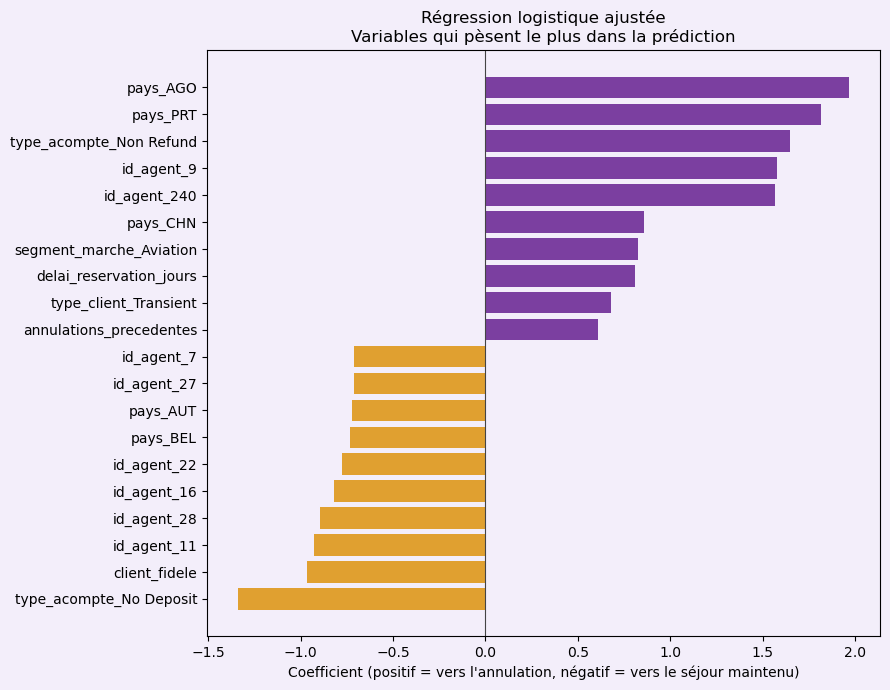

In [81]:
# Graphique des 10 coefficients les plus positifs et des 10 plus négatifs
os.makedirs('../assets/graphiques', exist_ok=True)

extremes = pd.concat([coefficients.head(10), coefficients.tail(10)]).iloc[::-1]
couleurs = ['#7b3fa0' if c > 0 else '#e0a030' for c in extremes['Coefficient']]

fig, ax = plt.subplots(figsize=(9, 7), facecolor='#f3eefa')
ax.set_facecolor('#f3eefa')
ax.barh(extremes['Variable'], extremes['Coefficient'], color=couleurs)
ax.axvline(0, color='#444444', linewidth=0.8)
ax.set_title("Régression logistique ajustée\nVariables qui pèsent le plus dans la prédiction")
ax.set_xlabel("Coefficient (positif = vers l'annulation, négatif = vers le séjour maintenu)")
plt.tight_layout()
plt.savefig('../assets/graphiques/importance_regression_logistique.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

**Lecture des coefficients**

Les variables qui poussent le plus vers l'annulation sont les pays AGO (1.970) et PRT (1.817) puis le type d'acompte Non Refund (1.647) et les agents 9 (1.579) et 240 (1.568). Il y a ensuite un écart net. Le coefficient suivant est le pays CHN (0.856) suivi du segment de marché Aviation (0.827) du délai de réservation (0.811) du type de client Transient (0.679) et du nombre d'annulations précédentes (0.610).

Les variables qui poussent le plus vers un séjour maintenu sont le type d'acompte No Deposit (-1.342) qui ressort nettement puis le client fidèle (-0.965). Suivent les agents 11 (-0.928) 28 (-0.896) 16 (-0.818) 22 (-0.774) 27 (-0.713) et 7 (-0.710) et les pays BEL (-0.735) et AUT (-0.721).

Certaines lectures sont logiques. Un délai de réservation plus long et des annulations précédentes vont vers l'annulation. Un client fidèle va vers le séjour maintenu.

Parmi les vingt coefficients affichés, huit sont des agents et cinq sont des pays. Le modèle s'appuie beaucoup sur des variables qui identifient un groupe précis. Les agents apparaissent des deux côtés. Les agents 9 et 240 poussent vers l'annulation alors que six autres poussent vers le séjour maintenu. Ces coefficients décrivent ce que le modèle a retenu et ne prouvent pas que l'agent ou le pays cause l'annulation.

Le type d'acompte apparaît aux deux extrémités. Non Refund va vers l'annulation et No Deposit vers le séjour maintenu. Ce résultat est surprenant puisqu'un acompte non remboursable devrait décourager l'annulation. On le vérifie ci-dessous directement dans les données.

In [82]:
# Taux d'annulation observé dans le train pour chaque type d'acompte
colonnes_acompte = [c for c in X_train_final.columns if c.startswith('type_acompte_')]
lignes = []

for col in colonnes_acompte:
    masque = X_train_final[col] == 1
    lignes.append({
        'Variable': col,
        'Réservations': int(masque.sum()),
        "Taux d'annulation": y_train[masque].mean()
    })

tableau_acompte = pd.DataFrame(lignes).set_index('Variable').round(3)
tableau_acompte

,Réservations,Taux d'annulation
Variable,,
type_acompte_No Deposit,68402,0.269
type_acompte_Non Refund,823,0.943
type_acompte_Refundable,84,0.250


**Vérification pour le type d'acompte**

Le résultat est confirmé par les données. Dans le jeu d'entraînement, 94.3 % des réservations avec un acompte non remboursable (Non Refund) ont été annulées. Ce taux est de 26.9 % pour les réservations sans acompte (No Deposit) et de 25.0 % pour les remboursables (Refundable). Le modèle ne se trompe donc pas. Il reproduit ce que montrent les données.

Le groupe Non Refund est petit. Il compte 823 réservations contre 68402 pour No Deposit. Le coefficient est élevé parce que le signal est très net, mais cette variable ne concerne qu'une petite part des réservations. Le groupe Refundable est encore plus petit (84 réservations) et ne figure pas parmi les coefficients extrêmes.

Les données ne disent pas pourquoi les réservations Non Refund sont presque toutes annulées. C'est un point à faire confirmer par l'hôtel. On le garde dans les limites de la conclusion.

### 8.2 Arbre de décision

L'arbre de décision ne donne pas de signe. Son importance mesure à quel point une variable aide à séparer les annulées des maintenues quand l'arbre pose ses questions. Les importances sont positives et leur somme vaut 1. On affiche les dix variables les plus importantes sous forme de tableau puis de graphique.

In [83]:
# Tableau des importances de l'arbre ajusté, de la plus forte à la plus faible
importances_arbre = pd.DataFrame({
    'Variable': X_train_final.columns,
    'Importance': modele_arbre_ajuste.feature_importances_
})
importances_arbre = importances_arbre.sort_values('Importance', ascending=False).reset_index(drop=True)

importances_arbre.head(10).round(3)

,Variable,Importance
0,pays_PRT,0.268
1,delai_reservation_jours,0.218
2,segment_marche_Online TA,0.124
3,id_agent_240,0.050
4,annulations_precedentes,0.039
5,type_client_Transient-Party,0.039
6,id_agent_9,0.035
7,id_agent_7,0.034
8,type_acompte_Non Refund,0.034
9,id_agent_241,0.033


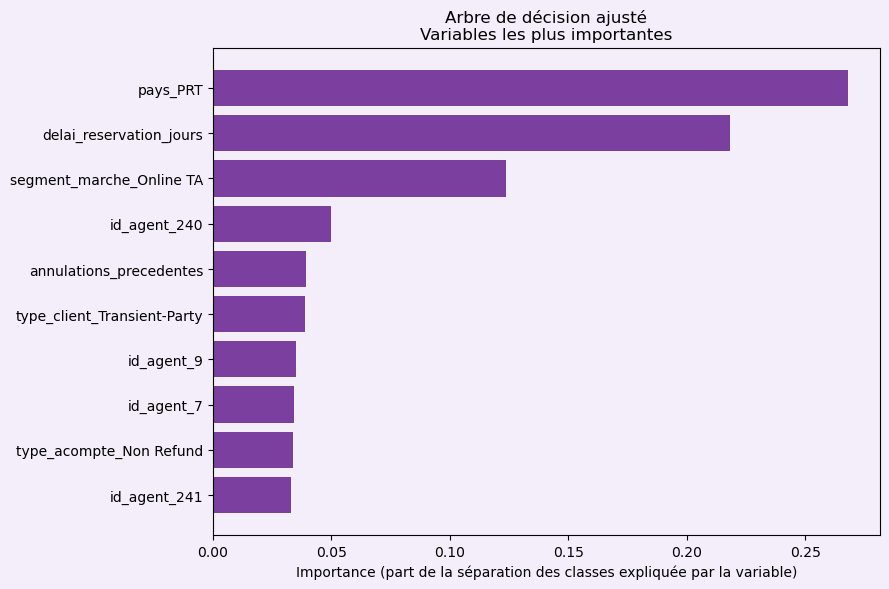

In [84]:
# Graphique des 10 variables les plus importantes de l'arbre
top10_arbre = importances_arbre.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6), facecolor='#f3eefa')
ax.set_facecolor('#f3eefa')
ax.barh(top10_arbre['Variable'], top10_arbre['Importance'], color='#7b3fa0')
ax.set_title("Arbre de décision ajusté\nVariables les plus importantes")
ax.set_xlabel("Importance (part de la séparation des classes expliquée par la variable)")
plt.tight_layout()
plt.savefig('../assets/graphiques/importance_arbre_decision.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

**Lecture des importances**

Trois variables concentrent l'essentiel du travail de l'arbre. Le pays PRT (0.268) arrive en tête devant le délai de réservation (0.218) et le segment de marché Online TA (0.124). À elles trois elles représentent plus de la moitié de l'importance totale (0.610). Les autres variables sont bien plus faibles, aucune ne dépasse 0.050.

Parmi les dix premières, quatre sont des agents (240, 9, 7 et 241). Viennent ensuite le nombre d'annulations précédentes (0.039) le type de client Transient-Party (0.039) et le type d'acompte Non Refund (0.034). Ces dix variables totalisent environ 0.87 de l'importance.

Ce classement recoupe celui de la régression logistique sur plusieurs points. Le pays PRT et les agents 240 et 9 ainsi que l'acompte Non Refund et le délai de réservation et les annulations précédentes figurent dans les deux. Le segment Online TA et l'agent 241 sont importants pour l'arbre mais n'apparaissent pas parmi les vingt coefficients extrêmes de la régression logistique. Les deux modèles ne mesurent pas la même chose. Un coefficient mesure la force d'une variable quand elle s'applique et l'importance de l'arbre mesure ce que la variable apporte dans ses questions.

L'importance n'a pas de signe. L'agent 7 est important pour l'arbre mais le coefficient de la régression logistique montre qu'il va vers le séjour maintenu (-0.710). Pour connaître le sens d'une variable on s'appuie donc sur la régression logistique.

Attention aux noms des catégories. Le type de client est Transient-Party ici et Transient dans la régression logistique. Ce sont deux catégories différentes.

### 8.3 Random Forest

La Random Forest calcule l'importance de chaque variable en moyenne sur tous ses arbres. Comme pour l'arbre de décision, elle n'a pas de signe et la somme des importances vaut 1. Faire la moyenne de cent arbres rend le classement plus stable que celui d'un arbre seul. On affiche les dix variables les plus importantes sous forme de tableau puis de graphique.

In [85]:
# Tableau des importances de la forêt ajustée, de la plus forte à la plus faible
importances_rf = pd.DataFrame({
    'Variable': X_train_final.columns,
    'Importance': modele_rf_ajuste.feature_importances_
})
importances_rf = importances_rf.sort_values('Importance', ascending=False).reset_index(drop=True)

importances_rf.head(10).round(3)

,Variable,Importance
0,delai_reservation_jours,0.235
1,pays_PRT,0.177
2,segment_marche_Online TA,0.066
3,id_agent_9,0.045
4,id_agent_240,0.043
5,nuits_semaine,0.034
6,type_client_Transient,0.025
7,annulations_precedentes,0.022
8,nuits_weekend,0.020
9,id_agent_7,0.020


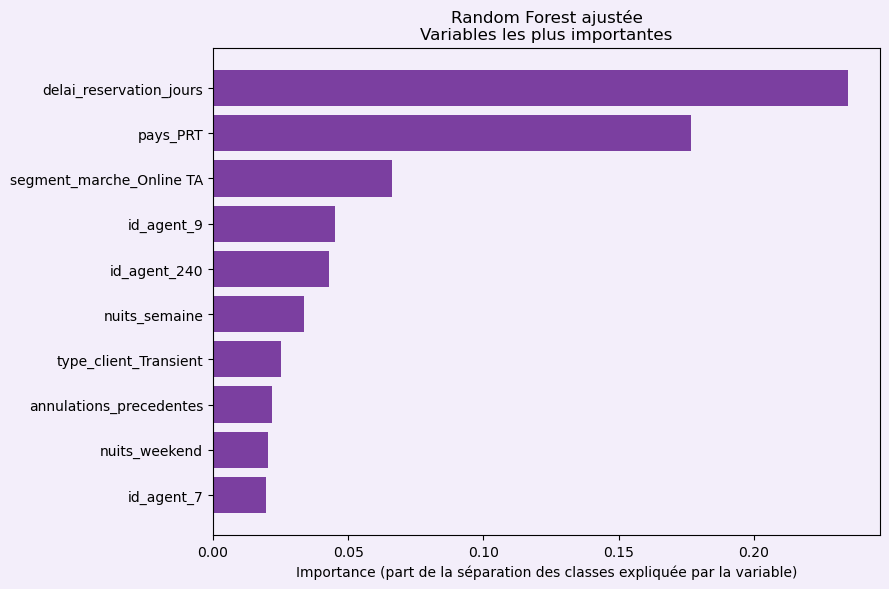

In [86]:
# Graphique des 10 variables les plus importantes de la forêt
top10_rf = importances_rf.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6), facecolor='#f3eefa')
ax.set_facecolor('#f3eefa')
ax.barh(top10_rf['Variable'], top10_rf['Importance'], color='#7b3fa0')
ax.set_title("Random Forest ajustée\nVariables les plus importantes")
ax.set_xlabel("Importance (part de la séparation des classes expliquée par la variable)")
plt.tight_layout()
plt.savefig('../assets/graphiques/importance_random_forest.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

**Lecture des importances**

Le délai de réservation (0.235) est la variable la plus importante pour la forêt. Il devance le pays PRT (0.177) et le segment de marché Online TA (0.066). Les trois premières variables représentent 0.478 de l'importance totale. Viennent ensuite deux agents (9 avec 0.045 et 240 avec 0.043) puis le nombre de nuits en semaine (0.034) le type de client Transient (0.025) le nombre d'annulations précédentes (0.022) le nombre de nuits de week-end (0.020) et l'agent 7 (0.020).

L'importance est plus répartie que dans l'arbre seul. Les dix premières variables totalisent environ 0.69 contre 0.87 pour l'arbre de décision, et les trois premières 0.478 contre 0.610. Faire voter cent arbres répartit le travail sur davantage de variables.

Par rapport à l'arbre, l'ordre des deux premières change. Le pays PRT était en tête pour l'arbre (0.268) devant le délai (0.218). La forêt met le délai en premier. Le nombre de nuits en semaine et celui de week-end n'apparaissaient pas dans les dix premières de l'arbre.

Comme pour l'arbre, l'importance n'a pas de signe. Pour connaître le sens d'une variable on s'appuie sur la régression logistique (par exemple, le pays PRT et un délai plus long poussent vers l'annulation).

L'importance calculée par la forêt a une limite connue. D'après la documentation de scikit-learn, elle a tendance à favoriser les variables numériques avec beaucoup de valeurs différentes comme le délai ou le nombre de nuits. Ce classement est à lire comme une indication et non comme une mesure exacte.

### 8.4 Comparaison

Le coefficient de la régression logistique et l'importance de l'arbre et de la forêt ne sont pas sur la même échelle. On les compare donc par leur rang. Le rang 1 est la variable la plus importante pour le modèle. Pour la régression logistique, on classe les variables selon la valeur absolue du coefficient. On garde les variables qui figurent dans les dix premières d'au moins un modèle et on les trie par rang moyen. Une colonne indique le sens du coefficient de la régression logistique.

In [87]:
# Rang de chaque variable pour chacun des trois modèles (1 = la plus importante)
comparaison = pd.DataFrame({
    'Variable': X_train_final.columns,
    'Coefficient': modele_logreg_ajuste.coef_[0],
    'Importance arbre': modele_arbre_ajuste.feature_importances_,
    'Importance forêt': modele_rf_ajuste.feature_importances_
})
comparaison['Rang régression logistique'] = comparaison['Coefficient'].abs().rank(ascending=False, method='first').astype(int)
comparaison['Rang arbre'] = comparaison['Importance arbre'].rank(ascending=False, method='first').astype(int)
comparaison['Rang forêt'] = comparaison['Importance forêt'].rank(ascending=False, method='first').astype(int)
comparaison['Sens (régression logistique)'] = comparaison['Coefficient'].apply(lambda c: 'annulation' if c > 0 else 'séjour maintenu')

# On garde les variables présentes dans les 10 premières d'au moins un modèle
colonnes_rang = ['Rang régression logistique', 'Rang arbre', 'Rang forêt']
dans_un_top10 = (comparaison[colonnes_rang] <= 10).any(axis=1)

tableau_comparaison = comparaison[dans_un_top10].copy()
tableau_comparaison['Rang moyen'] = tableau_comparaison[colonnes_rang].mean(axis=1).round(1)
tableau_comparaison = tableau_comparaison.sort_values('Rang moyen').reset_index(drop=True)

tableau_comparaison[['Variable'] + colonnes_rang + ['Rang moyen', 'Sens (régression logistique)']]

,Variable,Rang régression logistique,Rang arbre,Rang forêt,Rang moyen,Sens (régression logistique)
0,pays_PRT,2,1,2,1.7,annulation
1,id_agent_240,5,4,5,4.7,annulation
2,id_agent_9,4,7,4,5.0,annulation
3,delai_reservation_jours,13,2,1,5.3,annulation
4,type_acompte_Non Refund,3,9,11,7.7,annulation
5,id_agent_7,18,8,10,12.0,séjour maintenu
6,annulations_precedentes,24,5,8,12.3,annulation
7,type_client_Transient,20,13,7,13.3,annulation
8,type_client_Transient-Party,30,6,13,16.3,séjour maintenu
9,segment_marche_Online TA,59,3,3,21.7,séjour maintenu


**Lecture de la comparaison**

Trois variables figurent dans les dix premières des trois modèles. Il s'agit du pays PRT (rangs 2, 1 et 2) et des agents 240 (5, 4 et 5) et 9 (4, 7 et 4). Les trois vont vers l'annulation d'après la régression logistique. Le pays PRT est la variable la mieux classée en moyenne.

Certaines variables sont classées très différemment selon le modèle. Le délai de réservation est 13e pour la régression logistique mais 2e pour l'arbre et 1er pour la forêt. Le segment Online TA est 59e pour la régression logistique et 3e pour l'arbre et pour la forêt. Le nombre de nuits en semaine (88, 14 et 6) et celui de week-end (100, 16 et 9) comptent pour l'arbre et la forêt mais presque pas pour la régression logistique. Les deux modèles à base d'arbres s'appuient donc davantage sur ces variables numériques. Pour ces variables le signe de la régression logistique est à ignorer puisque leur coefficient est presque nul.

À l'inverse, des variables fortes pour la régression logistique le sont moins pour les arbres. Le pays AGO est 1er pour la régression logistique mais 17e pour l'arbre et 52e pour la forêt. Le pays CHN (10, 84 et 59) et les agents 11 (8, 92 et 62) et 28 (9, 107 et 78) suivent le même schéma. Le type d'acompte Non Refund reste dans les premiers rangs pour les trois (3, 9 et 11).

Les variables qui reviennent le plus dans les trois modèles dessinent un profil de réservation à risque. Il s'agit d'un client du pays PRT avec un délai de réservation long et passé par certains agents (240 et 9) avec un acompte non remboursable et des annulations précédentes. À l'inverse un client fidèle ou venant par d'autres agents (7, 11 et 28) est plus souvent maintenu. Ces variables sont associées à l'annulation dans les données. Elles ne prouvent pas qu'elles la causent.

### 8.5 Modèles avec les variables les plus importantes

Le tableau d'entrée a 114 colonnes et les importances montrent que beaucoup comptent très peu. On vérifie ici si on peut garder seulement les plus importantes sans perdre en performance. Les colonnes sont classées selon leur importance dans la Random Forest ajustée. Ce classement est calculé sur le jeu d'entraînement. On réentraîne ensuite les trois modèles ajustés avec les 57 puis les 28 puis les 15 colonnes les plus importantes et on les compare au modèle complet. Les paramètres restent ceux retenus en section 7.

In [93]:
# Classement des colonnes par importance dans la forêt ajustée (calculé sur le train)
classement_colonnes = pd.Series(modele_rf_ajuste.feature_importances_, index=X_train_final.columns)
classement_colonnes = classement_colonnes.sort_values(ascending=False)

def creer_modeles():
    # Recrée les trois modèles avec les paramètres retenus en section 7
    return {
        'Régression logistique': LogisticRegression(C=1, class_weight={0: 1, 1: 3}, max_iter=1000, random_state=42),
        'Arbre de décision': DecisionTreeClassifier(max_depth=10, min_samples_leaf=5,
                                                    class_weight={0: 1, 1: 2}, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, max_features=0.4, min_samples_leaf=10,
                                                class_weight={0: 1, 1: 3}, random_state=42, n_jobs=-1)
    }

# Réentraînement des trois modèles avec seulement les colonnes les plus importantes
nombres_colonnes = [X_train_final.shape[1], 57, 28, 15]
lignes = []

for k in nombres_colonnes:
    colonnes_gardees = list(classement_colonnes.index[:k])
    for nom, modele in creer_modeles().items():
        modele.fit(X_train_final[colonnes_gardees], y_train)
        proba = modele.predict_proba(X_test_final[colonnes_gardees])[:, 1]
        pred = (proba > 0.5).astype(int)
        lignes.append({
            'Colonnes gardées': k,
            'Modèle': nom,
            'Rappel': recall_score(y_test, pred),
            'Précision': precision_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'AUC': roc_auc_score(y_test, proba)
        })

tableau_selection = pd.DataFrame(lignes).set_index(['Colonnes gardées', 'Modèle']).round(3)
tableau_selection

Rappel  Précision     F1    AUC
Colonnes gardées Modèle                                                
114              Régression logistique   0.820      0.487  0.611  0.815
                 Arbre de décision       0.825      0.516  0.635  0.834
                 Random Forest           0.845      0.531  0.652  0.861
57               Régression logistique   0.825      0.486  0.612  0.810
                 Arbre de décision       0.823      0.516  0.634  0.833
                 Random Forest           0.847      0.527  0.650  0.858
28               Régression logistique   0.824      0.480  0.607  0.802
                 Arbre de décision       0.835      0.512  0.635  0.833
                 Random Forest           0.857      0.515  0.644  0.851
15               Régression logistique   0.821      0.473  0.600  0.796
                 Arbre de décision       0.838      0.510  0.635  0.833
                 Random Forest           0.872      0.503  0.638  0.840

**Résultat avec moins de colonnes**

On peut réduire de moitié le nombre de colonnes presque sans perte. Avec 57 colonnes au lieu de 114 les scores restent très proches pour les trois modèles. La Random Forest passe de 0.652 à 0.650 de F1 et son AUC de 0.861 à 0.858. L'arbre garde le même F1 (0.634 contre 0.635) et la même AUC (0.833 contre 0.834). La régression logistique a un F1 identique (0.611) et une AUC de 0.810 contre 0.815.

Avec 28 colonnes soit environ un quart la baisse est encore faible mais visible pour la forêt (F1 de 0.644 et AUC de 0.851). La régression logistique perd un peu (AUC de 0.802). L'arbre ne bouge presque pas.

Avec 15 colonnes la Random Forest a un rappel plus haut (0.872) mais sa précision descend à 0.503 et son AUC à 0.840. Le rappel monte parce que le modèle signale plus facilement des annulations, au prix de plus de fausses alertes. L'AUC qui baisse confirme que le classement des réservations est moins bon. Ce n'est donc pas une vraie amélioration.

L'arbre est le moins sensible à la réduction. Il n'utilise de toute façon qu'un nombre limité de colonnes. La régression logistique perd régulièrement un peu d'AUC (0.815, 0.810, 0.802 puis 0.796).

À toutes les tailles testées la Random Forest garde le meilleur F1 et la meilleure AUC des trois modèles. Le choix du modèle ne change pas.

On garde les 114 colonnes pour le modèle final puisqu'elles donnent les meilleures AUC et F1. Une version réduite à 57 colonnes est une option si on veut un modèle plus simple pour un résultat quasi identique.

<a id="choix"></a>
## 9. Choix du modèle


Les métriques de la section 7.4 donnent un premier classement. Pour choisir il faut aussi les traduire en situations concrètes pour l'hôtel. Chaque erreur du modèle a un coût différent.

- **Un faux négatif** est une annulation que le modèle n'a pas vue venir. L'hôtel ne s'y attend pas et risque de garder une chambre vide.
- **Un faux positif** est une fausse alerte. Le modèle annonce une annulation et le client vient finalement. L'hôtel peut perdre du temps à relancer ce client ou refuser une réservation à tort.

Notre priorité de départ est de retrouver un maximum d'annulations, donc de limiter les faux négatifs. On garde la précision comme garde-fou. On compare d'abord les trois modèles ajustés avec les nombres exacts de chaque type d'erreur sur le jeu de test.

### 9.1 Matrices de confusion des modèles ajustés

Le tableau donne pour chaque modèle le nombre de réservations dans chacune des quatre cases. Les matrices en dessous montrent la même chose sous forme de graphique.

In [88]:
# Prédictions des trois modèles ajustés sur le test avec le seuil de 0.5
modeles_ajustes = {
    'Régression logistique': modele_logreg_ajuste,
    'Arbre de décision': modele_arbre_ajuste,
    'Random Forest': modele_rf_ajuste
}
predictions_ajustees = {nom: (m.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)
                        for nom, m in modeles_ajustes.items()}

# Tableau des quatre cases de la matrice de confusion pour chaque modèle
lignes = []

for nom, pred in predictions_ajustees.items():
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    lignes.append({
        'Modèle': nom,
        'Vrais négatifs': vn,
        'Faux positifs': fp,
        'Faux négatifs': fn,
        'Vrais positifs': vp,
        'Alertes totales': fp + vp
    })

tableau_confusion = pd.DataFrame(lignes).set_index('Modèle')
tableau_confusion

,Vrais négatifs,Faux positifs,Faux négatifs,Vrais positifs,Alertes totales
Modèle,,,,,
Régression logistique,8384,4147,862,3935,8082
Arbre de décision,8825,3706,837,3960,7666
Random Forest,8939,3592,734,4063,7655


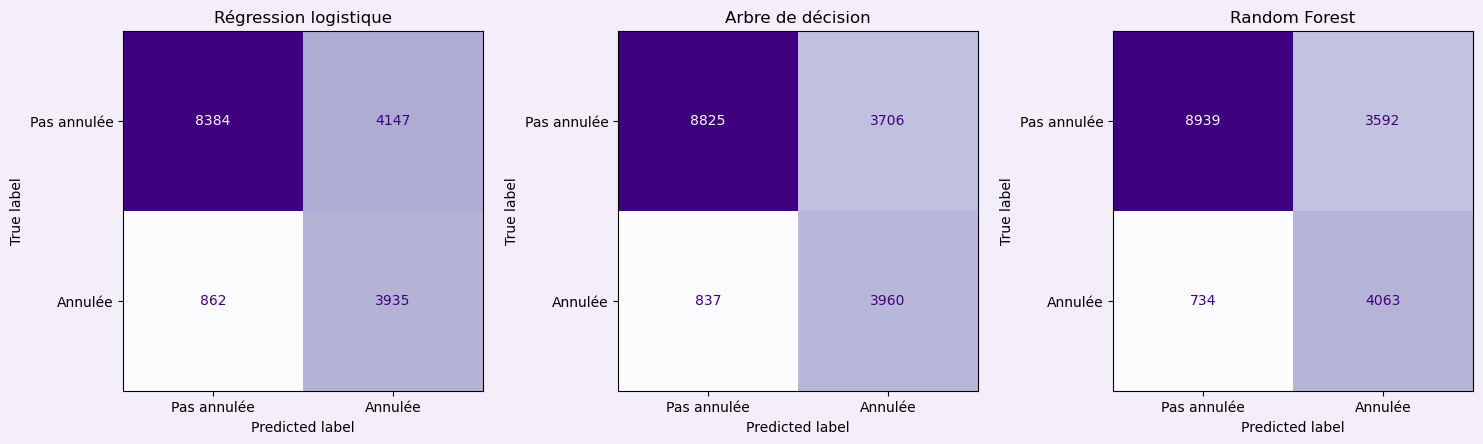

In [89]:
# Matrices de confusion des trois modèles ajustés côte à côte
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), facecolor='#f3eefa')

for ax, (nom, pred) in zip(axes, predictions_ajustees.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Pas annulée', 'Annulée'],
                                            cmap='Purples', ax=ax, colorbar=False, values_format='d')
    ax.set_title(nom)

plt.tight_layout()
plt.savefig('../assets/graphiques/matrices_confusion_ajustes.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

**Lecture des matrices de confusion**

Le jeu de test contient 4797 annulations réelles (faux négatifs plus vrais positifs, identique pour les trois modèles) et 12531 séjours maintenus.

La Random Forest fait le moins d'erreurs des deux types. Elle laisse passer 734 annulations contre 837 pour l'arbre et 862 pour la régression logistique. Elle émet aussi le moins de fausses alertes (3592 contre 3706 pour l'arbre et 4147 pour la régression logistique). Par rapport à la régression logistique, elle manque 128 annulations de moins et déclenche 555 fausses alertes de moins.

Sur les 4797 annulations, la forêt en repère 4063. Elle signale à tort 3592 séjours maintenus, soit moins d'une fausse alerte pour chaque annulation repérée. Au total elle émet 7655 alertes. Les nombres d'alertes des trois modèles sont proches (8082 pour la régression logistique et 7666 pour l'arbre). La forêt les utilise mieux, avec plus de vraies annulations parmi elles.

Les fausses alertes sont plus nombreuses que les annulations manquées. Ce n'est pas anormal puisqu'il y a beaucoup plus de séjours maintenus que d'annulations, et que le poids donné aux annulations pousse les modèles à signaler plus facilement.

### 9.2 Modèle retenu

On retient la Random Forest ajustée (100 arbres, max_features de 0.4, feuilles de 10 réservations minimum et poids de 3 pour la classe annulée).

- Elle a le meilleur rappel (0.847) et la meilleure précision (0.531) des trois modèles ajustés. Elle a aussi le meilleur F1 (0.653) et la meilleure AUC (0.861).
- Elle fait le moins de faux négatifs (734) et le moins de faux positifs (3592).
- Sa précision dépasse 0.5, ce qui veut dire que plus d'une alerte sur deux est une vraie annulation. La régression logistique est la seule à passer sous ce niveau (0.487).

Ce choix a des limites. Les paramètres et le modèle ont été choisis avec le jeu de test, donc les scores sont probablement un peu optimistes. Les poids de 2 et 3 supposent qu'une annulation manquée coûte deux à trois fois plus qu'une fausse alerte. Cette hypothèse doit être confirmée par l'hôtel. Enfin la Random Forest est moins lisible que la régression logistique. Son importance n'a pas de signe. Pour connaître le sens d'une variable il faut s'appuyer sur la régression logistique (section 8.1).

<a id="erreurs"></a>
## 10. Analyse des erreurs

Le modèle retenu est la Random Forest ajustée. On regarde ici les réservations sur lesquelles il se trompe pour savoir si elles ont un profil particulier. Pour cela on classe chaque réservation du jeu de test dans l'un des quatre groupes suivants.

- **Vrai positif.** Le modèle annonce une annulation et la réservation a bien été annulée.
- **Faux négatif.** Le modèle ne voit rien venir et la réservation a été annulée.
- **Faux positif.** Le modèle annonce une annulation à tort et le client est venu.
- **Vrai négatif.** Le modèle annonce un séjour maintenu et le client est venu.

On compare ensuite la moyenne des variables clés de la section 8 dans chaque groupe. Si les réservations qu'il rate ressemblent à celles qu'il classe bien, les données ne permettent pas de les distinguer.

### 10.1 Profil des quatre groupes

Pour les colonnes 0 ou 1 (pays, agent, segment, type de client, acompte et client fidèle) la moyenne est la part de réservations du groupe qui ont cette caractéristique. Pour le délai de réservation et les annulations précédentes la valeur est standardisée. Une valeur de 0 correspond à la moyenne générale. Une valeur positive indique un délai plus long que la moyenne et une valeur négative un délai plus court.

In [90]:
# Classement de chaque réservation du test selon le résultat de la Random Forest ajustée
pred_rf = (modele_rf_ajuste.predict_proba(X_test_final)[:, 1] > 0.5).astype(int)

analyse = X_test_final.copy()
analyse['Résultat'] = 'Vrai négatif'
analyse.loc[(y_test == 0) & (pred_rf == 1), 'Résultat'] = 'Faux positif'
analyse.loc[(y_test == 1) & (pred_rf == 0), 'Résultat'] = 'Faux négatif'
analyse.loc[(y_test == 1) & (pred_rf == 1), 'Résultat'] = 'Vrai positif'

In [91]:
# Moyenne des variables clés pour chacun des quatre groupes
variables_cles = ['pays_PRT', 'id_agent_240', 'id_agent_9', 'type_acompte_Non Refund',
                  'segment_marche_Online TA', 'type_client_Transient', 'client_fidele',
                  'delai_reservation_jours', 'annulations_precedentes']
ordre = ['Vrai positif', 'Faux négatif', 'Faux positif', 'Vrai négatif']

tableau_erreurs = analyse.groupby('Résultat')[variables_cles].mean().loc[ordre].round(3)
tableau_erreurs.insert(0, 'Réservations', analyse['Résultat'].value_counts().loc[ordre])

tableau_erreurs.T

Résultat,Vrai positif,Faux négatif,Faux positif,Vrai négatif
Réservations,4063.000,734.000,3592.000,8939.000
pays_PRT,0.403,0.422,0.299,0.266
id_agent_240,0.221,0.157,0.205,0.099
id_agent_9,0.512,0.279,0.591,0.144
type_acompte_Non Refund,0.050,0.004,0.001,0.000
segment_marche_Online TA,0.807,0.490,0.843,0.404
type_client_Transient,0.914,0.838,0.918,0.738
client_fidele,0.005,0.030,0.004,0.064
delai_reservation_jours,0.533,-0.336,0.389,-0.344
annulations_precedentes,0.065,-0.013,-0.071,-0.009


**Lecture du profil des quatre groupes**

Les effectifs sont ceux de la matrice de confusion de la 9.1 (4063 vrais positifs, 734 faux négatifs, 3592 faux positifs et 8939 vrais négatifs).

**Les annulations manquées (faux négatifs).** Elles ont un délai de réservation court (-0.336), comme les séjours maintenus bien classés (-0.344) et à l'opposé des annulations bien repérées (0.533). Elles passent moins souvent par l'agent 9 (0.279 contre 0.512) et le segment Online TA (0.490 contre 0.807). Elles ne sont presque jamais en acompte Non Refund (0.004 contre 0.050). Le modèle rate donc les annulations qui ressemblent à des séjours ordinaires.

**Les fausses alertes (faux positifs).** Elles ressemblent aux vraies annulations. Leur délai est long (0.389) et elles passent très souvent par l'agent 9 (0.591) et le segment Online TA (0.843) avec un type de client Transient (0.918). Ces valeurs sont proches de celles des vrais positifs (0.512 pour l'agent 9 et 0.807 pour Online TA et 0.914 pour Transient). L'agent 9 est même plus présent parmi les fausses alertes que parmi les vraies annulations. Seul le pays PRT les distingue des vrais positifs (0.299 contre 0.403). Le type d'acompte Non Refund est quasiment absent des fausses alertes (0.001).

Les clients fidèles sont presque absents des réservations signalées (0.005 pour les vrais positifs et 0.004 pour les faux positifs contre 0.064 pour les vrais négatifs). Le modèle ne les signale presque jamais.

Les erreurs viennent d'une confusion de profil. Avec les variables connues au moment de la réservation, certaines annulations ressemblent à des séjours maintenus et certains séjours maintenus ressemblent à des annulations. Le modèle ne dispose pas d'information qui les départage. Cela explique pourquoi le score s'arrête à ce niveau. Des variables connues plus tard dans la vie de la réservation pourraient aider à les distinguer. C'est une piste pour la suite.

### 10.2 Réservations les plus ratées

La 10.1 compare le profil moyen des groupes. On cherche ici où le modèle rate le plus d'annulations. Pour chaque caractéristique clé (pays, agent, segment de marché, type de client, acompte, client fidèle et hôtel) on regarde parmi les annulations réelles du jeu de test la part que le modèle n'a pas vue venir. On la compare à la part manquée sur l'ensemble des annulations. La colonne Annulations donne la taille du groupe pour juger de la solidité du résultat.

In [94]:
# Part d'annulations manquées par le modèle pour chaque groupe de réservations
annulees = (y_test == 1)
groupes = ['pays_PRT', 'id_agent_9', 'id_agent_240', 'segment_marche_Online TA', 'type_client_Transient',
           'type_client_Transient-Party', 'client_fidele', 'type_acompte_Non Refund', 'hotel']
lignes = []

for col in groupes:
    for valeur in [1, 0]:
        masque = annulees & (X_test_final[col] == valeur)
        total = int(masque.sum())
        if total == 0:
            continue
        manquees = int(((pred_rf == 0) & masque).sum())
        lignes.append({
            'Groupe': f'{col} = {valeur}',
            'Annulations': total,
            'Manquées': manquees,
            'Part manquée': manquees / total
        })

tableau_ratees = pd.DataFrame(lignes).set_index('Groupe').sort_values('Part manquée', ascending=False).round(3)

# Part manquée sur l'ensemble des annulations pour comparaison
part_globale = ((pred_rf == 0) & annulees).sum() / annulees.sum()
print("Part manquée sur l'ensemble des annulations", round(part_globale, 3))
tableau_ratees

Part manquée sur l'ensemble des annulations 0.153


,Annulations,Manquées,Part manquée
Groupe,,,
client_fidele = 1,41,22,0.537
segment_marche_Online TA = 0,1157,374,0.323
type_client_Transient-Party = 1,351,111,0.316
type_client_Transient = 0,470,119,0.253
id_agent_9 = 0,2512,529,0.211
hotel = 0,1618,306,0.189
id_agent_240 = 0,3784,619,0.164
type_acompte_Non Refund = 0,4591,731,0.159
pays_PRT = 1,1947,310,0.159


**Résultat par groupe**

Sur l'ensemble du jeu de test, le modèle rate 734 annulations sur 4797, soit 0.153. Ce tableau donne la part d'annulations manquées dans chaque groupe.

Hors segment Online TA, la part manquée est de 0.323 contre 0.099 pour Online TA, soit plus de trois fois plus. Les 374 annulations manquées hors Online TA représentent environ la moitié de toutes les annulations manquées. Le type d'acompte Non Refund est presque toujours repéré (3 annulations manquées sur 206).

Le pays PRT ne change presque rien (0.159 contre 0.149 pour les autres). La part manquée est plus élevée pour l'hôtel codé 0 (0.189) que pour l'hôtel codé 1 (0.135). Les clients fidèles ont la part la plus haute (0.537) mais ils ne sont que 41 annulations, donc ce résultat est fragile.

Ces écarts confirment la 10.1. Le modèle repère mieux les annulations qui ressemblent au profil typique et rate davantage les autres.

### 10.3 Conséquences pour l'hôtel

Cette dernière partie traduit les résultats du modèle retenu en chiffres utiles pour l'hôtel. On part du tableau de confusion de la Random Forest ajustée (9.1) et on calcule le nombre d'annulations repérées et manquées ainsi que le nombre de fausses alertes. On en déduit trois parts faciles à expliquer.

In [95]:
# Chiffres clés pour l'hôtel avec la Random Forest ajustée, tirés du tableau de confusion
rf = tableau_confusion.loc['Random Forest']
annulations_reelles = rf['Vrais positifs'] + rf['Faux négatifs']
sejours_maintenus = rf['Vrais négatifs'] + rf['Faux positifs']

chiffres_hotel = pd.Series({
    'Annulations réelles': annulations_reelles,
    'Annulations repérées': rf['Vrais positifs'],
    'Annulations manquées': rf['Faux négatifs'],
    'Séjours maintenus': sejours_maintenus,
    'Fausses alertes': rf['Faux positifs'],
    'Alertes totales': rf['Alertes totales'],
    'Part des annulations repérées': rf['Vrais positifs'] / annulations_reelles,
    'Part des séjours maintenus signalés à tort': rf['Faux positifs'] / sejours_maintenus,
    'Part des alertes qui sont de vraies annulations': rf['Vrais positifs'] / rf['Alertes totales']
}, name='Random Forest ajustée').round(3)

chiffres_hotel.to_frame()

,Random Forest ajustée
Annulations réelles,4797.000
Annulations repérées,4063.000
Annulations manquées,734.000
Séjours maintenus,12531.000
Fausses alertes,3592.000
Alertes totales,7655.000
Part des annulations repérées,0.847
Part des séjours maintenus signalés à tort,0.287
Part des alertes qui sont de vraies annulations,0.531


Sur le jeu de test, la Random Forest ajustée retrouve 4063 annulations sur 4797 et en laisse passer 734. Elle signale aussi à tort 3592 séjours qui ont finalement eu lieu, soit 0.287 des 12531 séjours maintenus. Sur les 7655 alertes émises, un peu plus d'une sur deux est une vraie annulation (0.531).

Ce que ces résultats permettent à l'hôtel.

- **Utiliser l'alerte comme un déclencheur léger.** Comme près de la moitié des alertes sont fausses, il vaut mieux des actions peu coûteuses (relance, demande de confirmation) que des mesures lourdes comme refuser une réservation.
- **Surveiller les profils à risque.** Les variables qui reviennent dans les trois modèles sont le pays PRT, les agents 240 et 9, le délai de réservation, l'acompte Non Refund et les annulations précédentes.
- **Ne pas se rassurer trop vite sans alerte.** Hors segment Online TA le modèle rate 0.323 des annulations contre 0.099 pour Online TA. Pour ces réservations l'absence d'alerte est moins fiable.

Le bon compromis entre annulations repérées et fausses alertes dépend du coût réel de chaque erreur pour l'hôtel. Nos poids de 2 et 3 supposent qu'une annulation manquée coûte deux à trois fois plus qu'une fausse alerte. Cette hypothèse doit être confirmée par l'hôtel. Le seuil de décision peut aussi être déplacé pour repérer plus ou moins d'annulations.

### 10.4 Règle de priorisation

La direction peut intervenir sur 100 réservations parmi 1 000 à venir, soit 10 %. Le seuil de 0.5 signale beaucoup trop de réservations pour que l'hôtel puisse toutes les traiter. On change donc de méthode avec le modèle retenu, la Random Forest ajustée.

Le modèle donne une probabilité d'annulation pour chaque réservation. On les classe de la plus risquée à la moins risquée et on garde les 10 % du haut. Sur le jeu de test cela fait 1732 réservations. Ce sont celles que le modèle juge les plus à risque.

On regarde ensuite dans les vraies données combien de ces réservations ont réellement été annulées. On utilise trois indicateurs.

- **Précision.** Part des réservations sélectionnées qui ont vraiment été annulées.
- **Part des annulations captées.** Part de toutes les annulations du jeu de test qui se trouvent dans la sélection.
- **Gain par rapport au hasard.** La précision divisée par la part d'annulations du jeu de test. Un gain de 2 veut dire que la sélection contient deux fois plus d'annulations qu'un choix au hasard.

In [97]:
# Règle de priorisation avec la Random Forest ajustée, on contacte les 10 % de réservations avec la plus forte probabilité d'annulation
part_contactee = 0.10
nb_contactees = int(len(y_test) * part_contactee)
taux_base = y_test.mean()
nb_annulations_total = int(y_test.sum())

# Classement des réservations par probabilité d'annulation décroissante
modele_rf = modeles_compares['Random Forest (ajustée)']
proba = modele_rf.predict_proba(X_test_final)[:, 1]
indices = np.argsort(proba)[::-1][:nb_contactees]
annulees_contactees = int(y_test.iloc[indices].sum())

# Ce qu'on obtiendrait en choisissant au hasard le même nombre de réservations
annulees_hasard = nb_contactees * taux_base

tableau_priorisation = pd.DataFrame({
    'Annulations dans la sélection': [annulees_hasard, annulees_contactees],
    'Précision': [taux_base, annulees_contactees / nb_contactees],
    'Part des annulations captées': [annulees_hasard / nb_annulations_total, annulees_contactees / nb_annulations_total],
    'Gain par rapport au hasard': [1.0, (annulees_contactees / nb_contactees) / taux_base]
}, index=['Choix au hasard', 'Random Forest (ajustée)']).round(3)

print("Réservations contactées", nb_contactees, "| annulations dans le jeu de test", nb_annulations_total, "| part d'annulations", round(taux_base, 3))
tableau_priorisation

Réservations contactées 1732 | annulations dans le jeu de test 4797 | part d'annulations 0.277


,Annulations dans la sélection,Précision,Part des annulations captées,Gain par rapport au hasard
Choix au hasard,479.479,0.277,0.100,1.000
Random Forest (ajustée),1368.000,0.790,0.285,2.853


**Résultat pour la Random Forest ajustée**

Sur les 1732 réservations sélectionnées, 1368 sont de vraies annulations. La précision est de 0.790. En choisissant 1732 réservations au hasard on en attendrait environ 479 annulées, soit une précision de 0.277 qui correspond à la part d'annulations du jeu de test. Le gain est de 2.853. La sélection contient donc presque trois fois plus d'annulations qu'un choix au hasard.

**Les fausses alertes**

Les 1732 réservations sont bien celles que le modèle juge les plus risquées. Mais 364 d'entre elles (1732 moins 1368) n'ont finalement pas été annulées. Ce sont des fausses alertes. Sur 10 réservations contactées environ 2 auraient maintenu leur séjour sans intervention.

**Limites**

- La sélection capte 28.5 % des annulations du jeu de test. Les autres ne sont pas atteintes car l'hôtel ne peut traiter que 10 % des réservations. Même avec un classement parfait on ne pourrait pas dépasser 36 % (1732 sur 4797 annulations).
- Les paramètres ayant été réglés sur le jeu de test, ces scores sont probablement un peu optimistes.

<a id="conclusion"></a>
## 11. Conclusion

### Ce que nous avons fait
L'objectif était de prédire l'annulation d'une réservation à partir des informations connues le jour de la réservation. Nous sommes partis du fichier nettoyé et nous avons gardé 18 variables qui deviennent 114 colonnes après l'encodage. Le jeu d'entraînement compte 69309 réservations et le jeu de test 17328.

Nous avons comparé un modèle de référence et trois modèles (régression logistique, arbre de décision et Random Forest). Pour chacun nous avons testé les paramètres un par un puis en combinaisons. Nous avons gardé le rappel de la classe annulée comme critère principal parce que l'hôtel veut retrouver un maximum d'annulations. La précision sert de garde-fou.

### Résultats
Le modèle retenu est la Random Forest ajustée. Elle obtient un rappel de 0.847 contre 0.269 pour le modèle de référence et 0.553 pour la Random Forest de départ. Sa précision est de 0.531 contre 0.645 au départ. L'ajustement a donc échangé de la précision contre du rappel. Son F1 est de 0.653 et son AUC de 0.861.

Elle est la meilleure des trois modèles ajustés sur toutes les métriques et sur les deux types d'erreur (734 annulations manquées et 3592 fausses alertes). Les trois modèles s'accordent sur un noyau de variables (pays PRT et agents 240 et 9). Le modèle rate davantage les annulations qui sortent du profil typique, comme celles des autres segments que Online TA.

Pour une action ciblée, on classe les réservations par probabilité d'annulation et ne contacter que les 10 % du haut. Sur le jeu de test cela représente 1732 réservations dont 1368 sont de vraies annulations, soit une précision de 0.790. C'est presque trois fois mieux qu'un choix au hasard (0.277). Ces réservations captent 28.5 % de toutes les annulations.

### Limites
- Le jeu de test a servi à choisir les paramètres et le modèle. Il n'y avait pas de jeu totalement neuf, donc les scores sont probablement un peu optimistes.
- Nous avons gardé le seuil de 0.5 pour tous les modèles sans tester d'autres valeurs.
- Les poids donnés aux annulations supposent qu'une annulation manquée coûte deux à trois fois plus qu'une fausse alerte. L'hôtel doit confirmer ce coût.
- Le modèle ne connaît que ce qui est disponible le jour de la réservation. Certaines annulations ressemblent à des séjours maintenus et inversement, ce qui limite le score.
- Les importances décrivent ce que le modèle a retenu et ne prouvent pas une cause. La forte association entre l'acompte Non Refund et l'annulation (94.3 % d'annulations dans ce groupe) est à faire confirmer par l'hôtel.
- Certains groupes sont petits (41 annulations de clients fidèles) et leurs résultats sont fragiles.
- Si l'hôtel ne peut traiter que 10 % des réservations, il atteint au mieux 28.5 % des annulations avec notre modèle. Le maximum théorique est de 36 %. Environ 2 contacts sur 10 concernent un client qui aurait maintenu son séjour.

### Améliorations possibles
- Tester les modèles sans les colonnes d'agents pour mesurer leur apport.
- Regrouper les catégories rares (agents et pays) pour réduire le nombre de colonnes.
- Tester d'autres seuils de décision.
- Régler les paramètres par validation croisée sur le jeu d'entraînement et garder le test pour une évaluation finale.
- Essayer des modèles plus avancés.
- Version plus récente de scikit-learn